In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import sqlite3

from scipy.stats import ttest_ind
import scipy.stats as stats

warnings.filterwarnings('ignore')

In [2]:
#creating database connection
conn = sqlite3.connect('inventory.db')

# fetching vendor summary table
df = pd.read_sql_query('select * from vendor_sales_summary', conn)
df.head()

,VendorNumber,VendorName,Brand,Description,PurchasePrice,ActualPrice,Volume,TotalPurchaseQuantity,TotalPurchaseDollars,TotalSalesQuantity,TotalSalesDollars,TotalSalesPrice,TotalExciseTax,FreightCost,GrossProfit,ProfitMargin,StockTurnover,SalesToPurchaseRatio
0,1128,BROWN-FORMAN CORP,1233,Jack Daniels No 7 Black,26.27,36.99,1750.0,145080,3811251.60,106429.0,3843192.71,543776.67,195550.63,68601.68,31941.11,0.831109,0.733588,1.008381
1,4425,MARTIGNETTI COMPANIES,3405,Tito's Handmade Vodka,23.19,28.99,1750.0,164038,3804041.22,123703.0,3742726.93,454354.54,227292.20,144929.24,-61314.29,-1.638225,0.754112,0.983882
2,17035,PERNOD RICARD USA,8068,Absolut 80 Proof,18.24,24.99,1750.0,187407,3418303.68,147904.0,3606744.46,373763.93,271761.04,123780.22,188440.78,5.224678,0.789213,1.055127
3,3960,DIAGEO NORTH AMERICA INC,4261,Capt Morgan Spiced Rum,16.17,22.99,1750.0,201682,3261197.94,138052.0,3150860.48,339136.98,253659.44,257032.07,-110337.46,-3.501820,0.684503,0.966167
4,3960,DIAGEO NORTH AMERICA INC,3545,Ketel One Vodka,21.89,29.99,1750.0,138109,3023206.01,101402.0,3180678.98,438847.51,186314.59,257032.07,157472.97,4.950923,0.734217,1.052088


In [3]:
# summary statistics
df.describe().T

,count,mean,std,min,25%,50%,75%,max
VendorNumber,10648.0,10640.705203,18700.404409,2.000000,3943.500000,7153.000000,9552.000000,1.733570e+05
Brand,10648.0,18054.503193,12643.196784,58.000000,5816.500000,18776.500000,25521.250000,9.063100e+04
PurchasePrice,10648.0,24.402095,109.483355,0.360000,6.840000,10.450000,19.470000,5.681810e+03
ActualPrice,10648.0,35.671184,148.534066,0.490000,10.990000,15.990000,28.990000,7.499990e+03
Volume,10648.0,847.883875,665.354152,50.000000,750.000000,750.000000,750.000000,2.000000e+04
TotalPurchaseQuantity,10648.0,3145.159936,11113.367455,1.000000,36.000000,261.000000,1981.250000,3.376600e+05
TotalPurchaseDollars,10648.0,30138.163064,123277.154715,0.710000,452.857500,3646.725000,20764.170000,3.811252e+06
TotalSalesQuantity,10648.0,2343.379602,8461.820048,0.000000,22.000000,176.000000,1417.250000,2.651660e+05
TotalSalesDollars,10648.0,31920.796891,127010.256309,0.000000,455.880000,3744.050000,21429.902500,3.843193e+06
TotalSalesPrice,10648.0,14465.090460,35385.232230,0.000000,159.385000,1963.885000,11993.690000,5.437767e+05


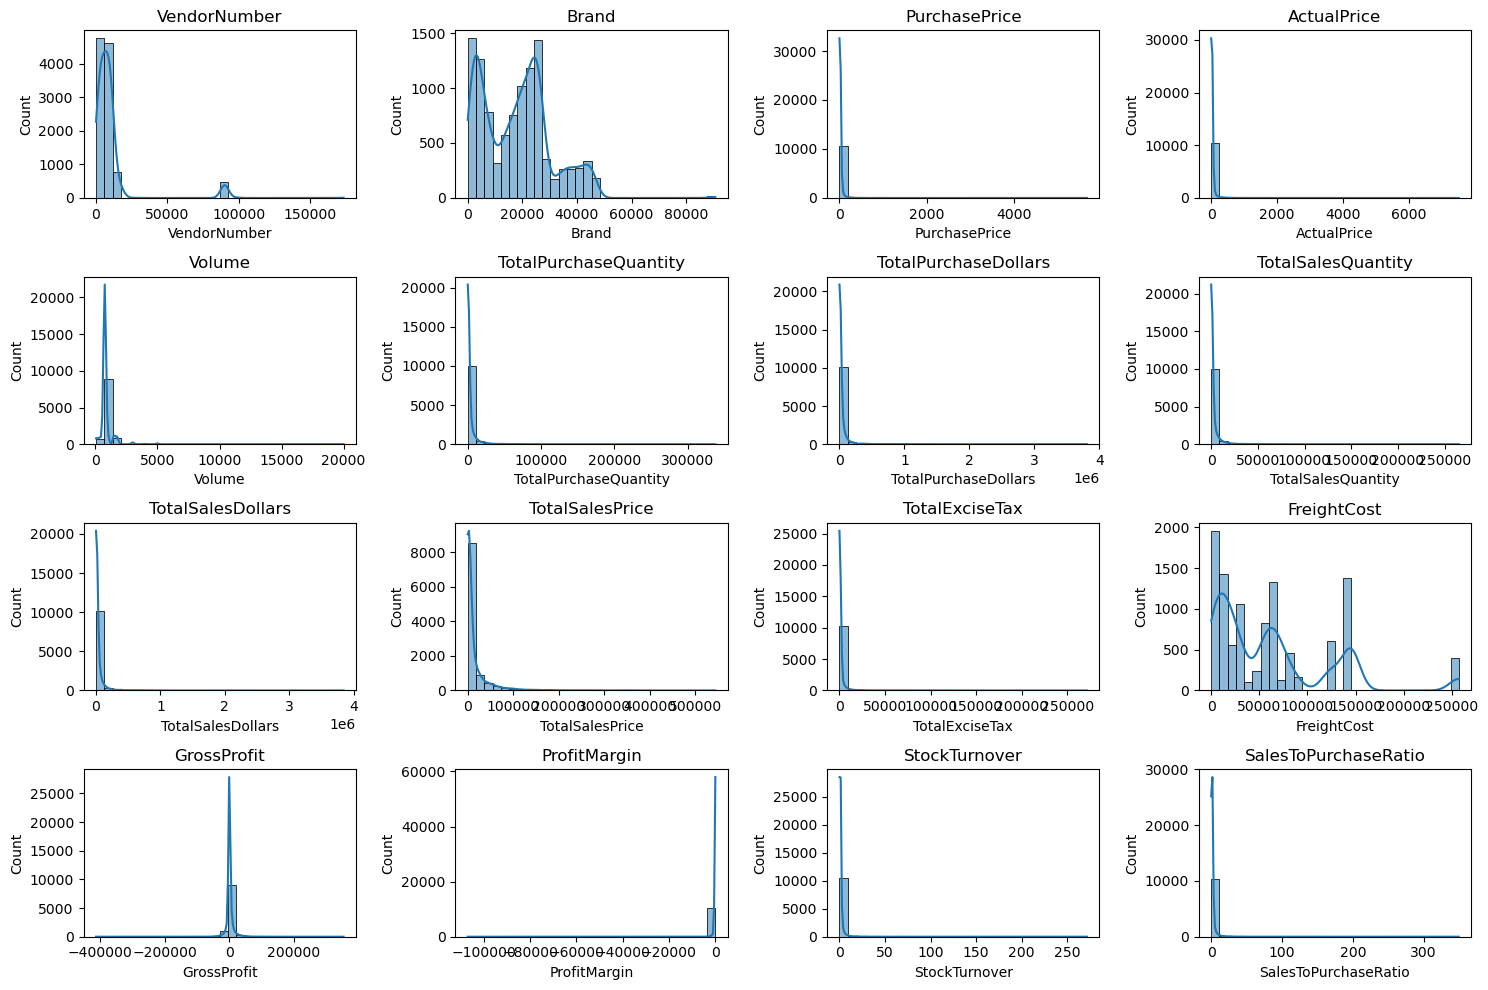

In [4]:
#Distribution Plots for Numerical Columns
numerical_cols = df.select_dtypes(include=np.number).columns

plt.figure(figsize=(15,10))
for i, col in enumerate(numerical_cols):
    plt.subplot(4, 4, i+1) #Adjust grid layout as needed
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(col)
plt.tight_layout()
plt.show()



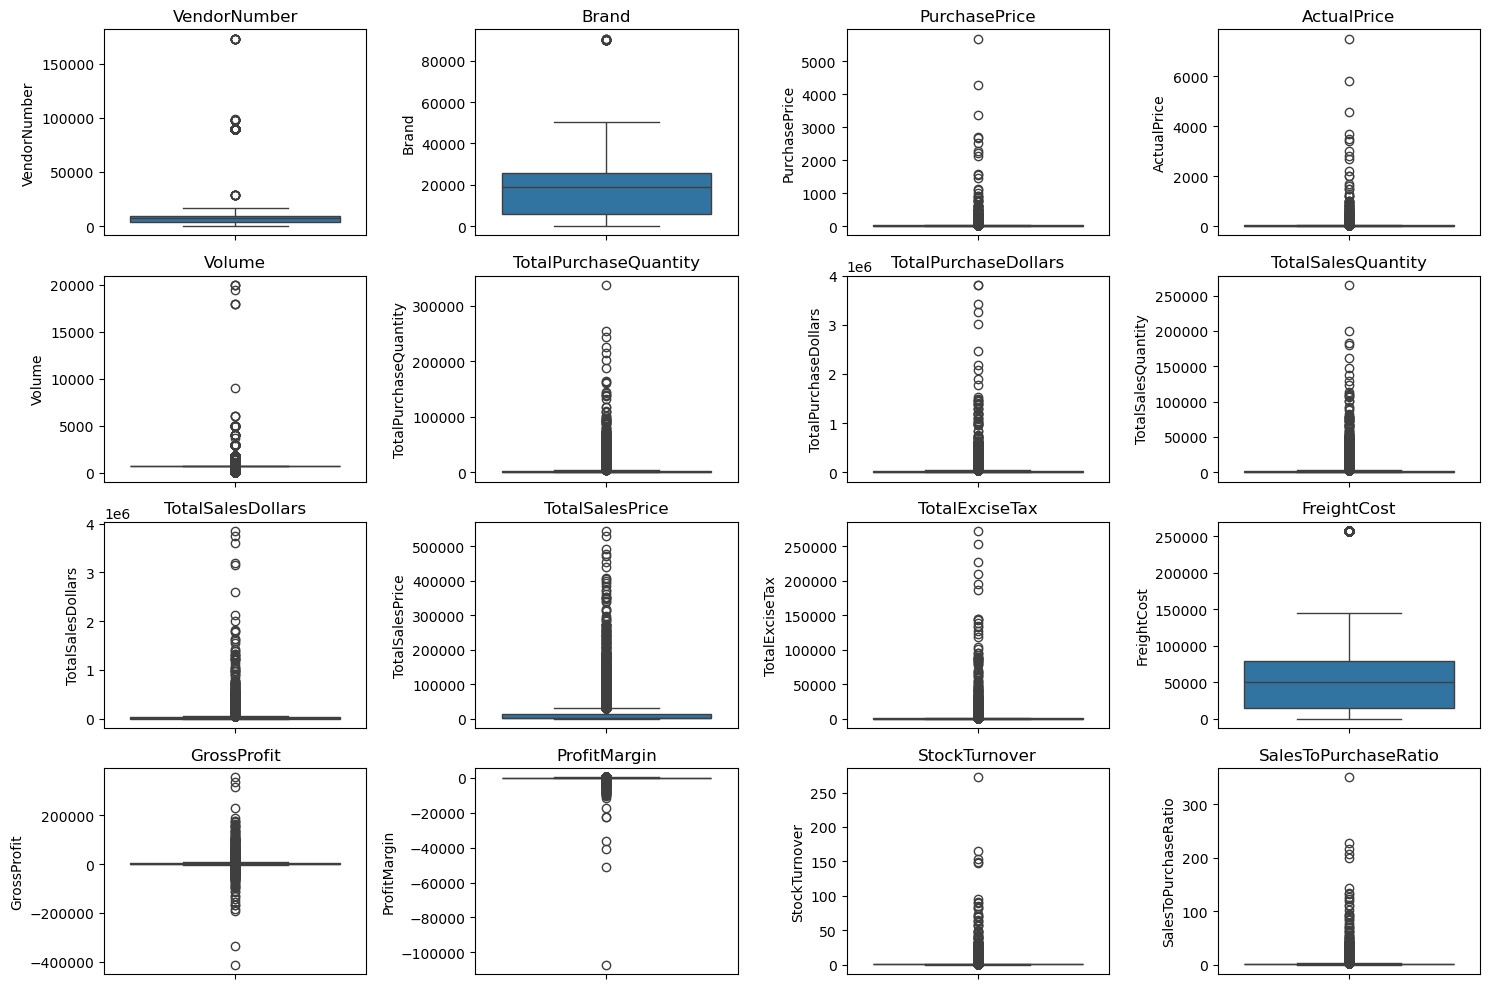

In [5]:
plt.figure(figsize=(15,10))
for i, col in enumerate(numerical_cols):
    plt.subplot(4, 4, i+1) #Adjust grid layout as needed
    sns.boxplot(y=df [col])
    plt.title(col)
plt.tight_layout()
plt.show()



In [6]:

## Summary Statistics Insights:
### Negative & Zero Values:
''' **Gross Profit:** Minimum value is -52,002.78, indicating losses. Some products or transactions may be selling at a loss due to high costs or selling at discounts lower than the purchase price.
- **Profit Margin:** Has a minimum of -∞, which suggests cases where revenue is zero or even lower than costs.
- **Total Sales Quantity & Sales Dollars:** Minimum values are 0, meaning some products were purchased but never sold. These could be slow-moving or obsolete stock.

### Outliers Indicated by High Standard Deviations:
- **Purchase & Actual Prices:** The max values (5,681.81 & 7,499.99) are significantly higher than the mean (24.39 & 35.64), indicating potential premium products.
- **Freight Cost:** Huge variation, from 0.09 to 257,032.07, suggests logistics inefficiencies or bulk shipments.
- **Stock Turnover:** Ranges from 0 to 274.5, implying some products sell extremely fast while others remain in stock indefinitely. Value more than 1 indicates that sold quantity for that product is higher than purchased quantity due to either sales being fulfilled from older stock.'''

' **Gross Profit:** Minimum value is -52,002.78, indicating losses. Some products or transactions may be selling at a loss due to high costs or selling at discounts lower than the purchase price.\n- **Profit Margin:** Has a minimum of -∞, which suggests cases where revenue is zero or even lower than costs.\n- **Total Sales Quantity & Sales Dollars:** Minimum values are 0, meaning some products were purchased but never sold. These could be slow-moving or obsolete stock.\n\n### Outliers Indicated by High Standard Deviations:\n- **Purchase & Actual Prices:** The max values (5,681.81 & 7,499.99) are significantly higher than the mean (24.39 & 35.64), indicating potential premium products.\n- **Freight Cost:** Huge variation, from 0.09 to 257,032.07, suggests logistics inefficiencies or bulk shipments.\n- **Stock Turnover:** Ranges from 0 to 274.5, implying some products sell extremely fast while others remain in stock indefinitely. Value more than 1 indicates that sold quantity for that pr

In [7]:
# let's filter the data by removing inconsistencies

df = pd.read_sql_query("""
SELECT * FROM vendor_sales_summary
WHERE GrossProfit > 0
AND ProfitMargin > 0
AND TotalSalesQuantity > 0
""", conn)

In [8]:
print("Filtered data shape:", df.shape)

display(df.head(10))

Filtered data shape: (6511, 18)


,VendorNumber,VendorName,Brand,Description,PurchasePrice,ActualPrice,Volume,TotalPurchaseQuantity,TotalPurchaseDollars,TotalSalesQuantity,TotalSalesDollars,TotalSalesPrice,TotalExciseTax,FreightCost,GrossProfit,ProfitMargin,StockTurnover,SalesToPurchaseRatio
0,1128,BROWN-FORMAN CORP,1233,Jack Daniels No 7 Black,26.27,36.99,1750.0,145080,3811251.60,106429.0,3843192.71,543776.67,195550.63,68601.68,31941.11,0.831109,0.733588,1.008381
1,17035,PERNOD RICARD USA,8068,Absolut 80 Proof,18.24,24.99,1750.0,187407,3418303.68,147904.0,3606744.46,373763.93,271761.04,123780.22,188440.78,5.224678,0.789213,1.055127
2,3960,DIAGEO NORTH AMERICA INC,3545,Ketel One Vodka,21.89,29.99,1750.0,138109,3023206.01,101402.0,3180678.98,438847.51,186314.59,257032.07,157472.97,4.950923,0.734217,1.052088
3,480,BACARDI USA INC,3858,Grey Goose Vodka,17.77,23.99,750.0,138809,2466635.93,108221.0,2587588.79,360454.53,85211.92,89286.27,120952.86,4.674346,0.779640,1.049036
4,3960,DIAGEO NORTH AMERICA INC,3489,Tanqueray,20.73,27.99,1750.0,91835,1903739.55,72520.0,2132902.80,408250.75,133244.12,257032.07,229163.25,10.744196,0.789677,1.120375
5,12546,JIM BEAM BRANDS COMPANY,1376,Jim Beam,16.29,21.99,1750.0,108866,1773427.14,77967.0,1815658.33,347410.04,143250.33,123880.97,42231.19,2.325944,0.716174,1.023813
6,17035,PERNOD RICARD USA,2585,Jameson Irish Whiskey,16.42,22.99,750.0,93205,1530426.10,66419.0,1546659.81,348667.66,52291.85,123780.22,16233.71,1.049598,0.712612,1.010607
7,480,BACARDI USA INC,2663,Dewars White Label,21.42,29.99,1750.0,69001,1478001.42,51520.0,1631494.80,399569.97,94660.50,89286.27,153493.38,9.408144,0.746656,1.103852
8,10000,MAJESTIC FINE WINES,6570,Kendall Jackson Chard Vt RSV,6.77,10.99,750.0,215668,1460072.36,162282.0,1793517.34,153583.92,18242.51,17587.59,333444.98,18.591679,0.752462,1.228376
9,9165,ULTRA BEVERAGE COMPANY LLP,3650,Patron Silver Tequila,33.81,48.99,750.0,42951,1452173.31,33269.0,1599373.31,529718.10,26193.15,68054.70,147200.00,9.203605,0.774580,1.101365


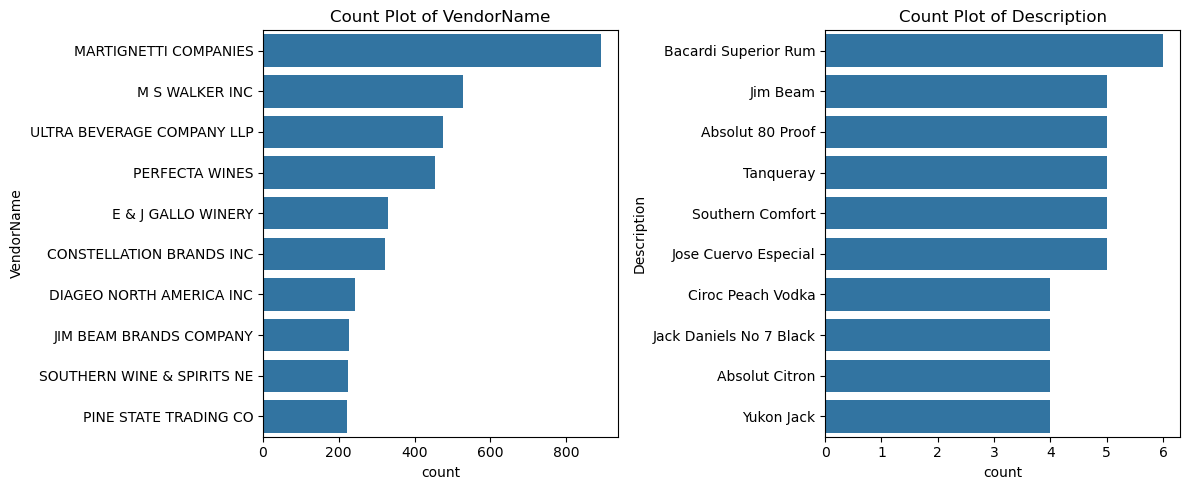

In [130]:
# Count Plots for Categorical Columns

categorical_cols = ["VendorName", "Description"]

plt.figure(figsize=(12, 5))

for i, col in enumerate(categorical_cols, 1):
    plt.subplot(1, 2, i)
    sns.countplot(
        y=df[col],
        order=df[col].value_counts().index[:10]
    )  # Top 10 categories

    plt.title(f"Count Plot of {col}")

plt.tight_layout()
plt.show()

In [131]:
# Select numerical columns
numerica_cols = df.select_dtypes(include=np.number).columns.tolist()

print("Numerical columns:")
print(numerica_cols)


Numerical columns:
['VendorNumber', 'Brand', 'PurchasePrice', 'ActualPrice', 'Volume', 'TotalPurchaseQuantity', 'TotalPurchaseDollars', 'TotalSalesQuantity', 'TotalSalesDollars', 'TotalSalesPrice', 'TotalExciseTax', 'FreightCost', 'GrossProfit', 'ProfitMargin', 'StockTurnover', 'SalesToPurchaseRatio']


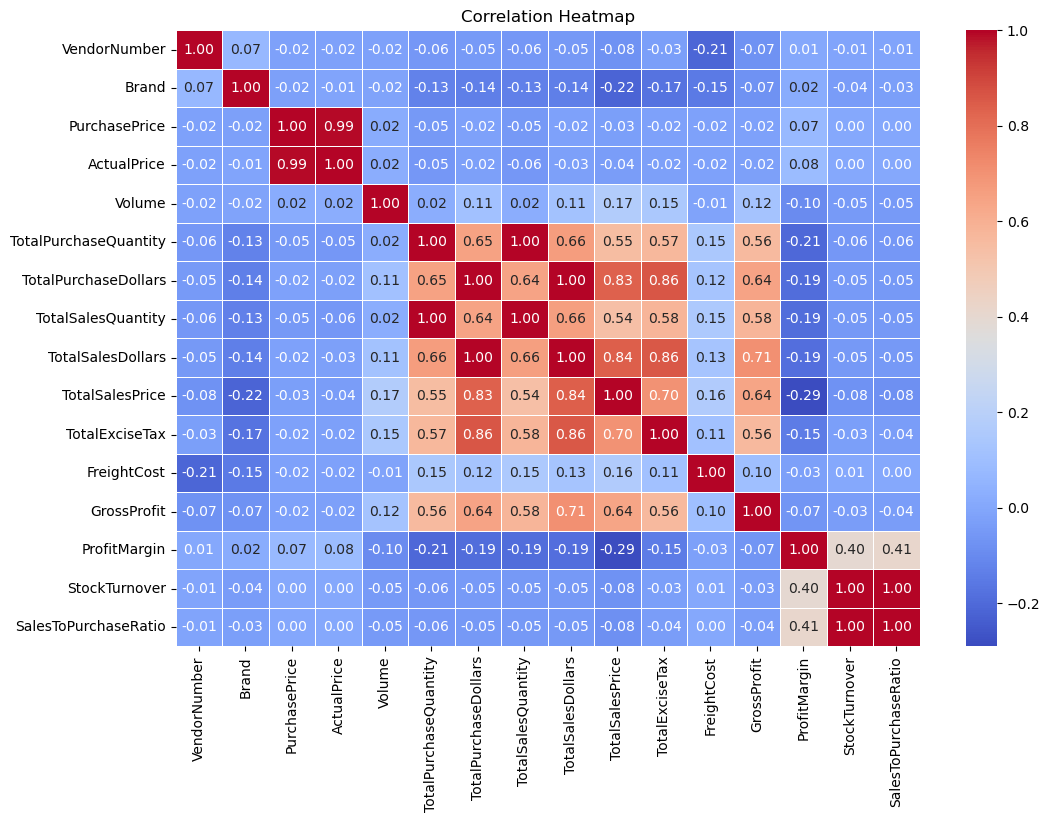

In [132]:
# Correlation Heatmap

plt.figure(figsize=(12, 8))

correlation_matrix = df[numerica_cols].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.show()

In [133]:
# Identify brands that need promotional or pricing adjustments
# Lower sales performance but higher profit margins

brand_performance = df.groupby('Description').agg({
    'TotalSalesDollars': 'sum',
    'ProfitMargin': 'mean'
}).reset_index()

display(brand_performance.head(10))

,Description,TotalSalesDollars,ProfitMargin
0,10 Span Cab Svgn CC,2306.92,7.332721
1,10 Span Chard CC,2951.06,18.644826
2,10 Span Pnt Gris Monterey Cy,1902.46,25.822356
3,10 Span Pnt Nr CC,2089.71,13.342521
4,12 Days of Pearls Gift Set,309.69,97.678323
5,13 Celsius Svgn Bl,25611.90,43.738418
6,14 Hands Cab Svgn Wash,202336.86,16.480166
7,14 Hands Chard Wash,44823.63,20.009491
8,14 Hands Hot to Trot Red,124983.78,11.982947
9,14 Hands Hot to Trot White,13075.33,25.699772


In [134]:
low_sales_threshold = brand_performance['TotalSalesDollars'].quantile(0.15)
high_margin_threshold = brand_performance['ProfitMargin'].quantile(0.85)

In [135]:
low_sales_threshold

np.float64(548.612)

In [136]:
high_margin_threshold

np.float64(69.92024745501641)

In [137]:
# Filter brands with low sales but high profit margins

target_brands = brand_performance[
    (brand_performance['TotalSalesDollars'] <= low_sales_threshold) &
    (brand_performance['ProfitMargin'] >= high_margin_threshold)
]

print("Brands with Low Sales but High Profit Margins:")

display(target_brands.sort_values('TotalSalesDollars'))

Brands with Low Sales but High Profit Margins:


,Description,TotalSalesDollars,ProfitMargin
1694,Concannon Glen Ellen Wh Zin,15.95,83.448276
1783,Crown Royal Apple,27.86,89.806174
4841,Sauza Sprklg Wild Berry Marg,27.96,82.153076
3752,Merry Irish Cream Liqueur,35.97,73.533500
5594,Tracia Syrah,44.94,88.495772
...,...,...,...
2904,Il Poggione di Montalcino,536.97,78.212936
1048,Casa Liliana Good Chard,538.51,94.986166
1844,Dad's Hat Rye Whiskey,538.89,81.851584
1727,Copain Wentzel Pnt Nr,539.91,85.475357


In [138]:
brand_performance = brand_performance[brand_performance['TotalSalesDollars']<1000] # for better visulaization

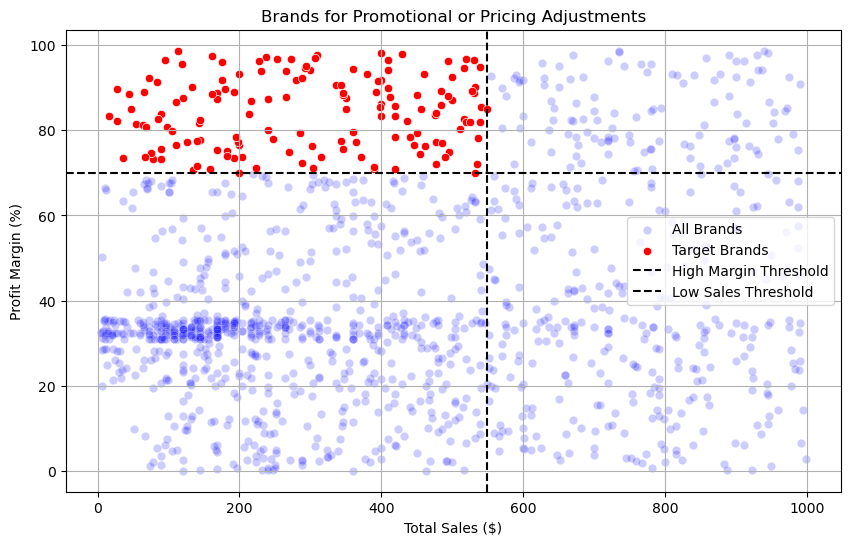

In [139]:
# Scatter plot for brand performance

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=brand_performance,
    x='TotalSalesDollars',
    y='ProfitMargin',
    color='blue',
    label='All Brands',
    alpha=0.2
)

sns.scatterplot(
    data=target_brands,
    x='TotalSalesDollars',
    y='ProfitMargin',
    color='red',
    label='Target Brands'
)

plt.axhline(
    high_margin_threshold,
    linestyle='--',
    color='black',
    label='High Margin Threshold'
)

plt.axvline(
    low_sales_threshold,
    linestyle='--',
    color='black',
    label='Low Sales Threshold'
)

plt.xlabel("Total Sales ($)")
plt.ylabel("Profit Margin (%)")
plt.title("Brands for Promotional or Pricing Adjustments")
plt.legend()
plt.grid(True)
plt.show()

In [140]:
def format_dollars(value):
    if value >= 1_000_000:
        return f"${value / 1_000_000:.2f}M"
    elif value >= 1_000:
        return f"${value / 1_000:.2f}K"
    else:
        return str(value)

In [141]:
# Top Vendors & Brands by Sales Performance

top_vendors = df.groupby("VendorName")["TotalSalesDollars"].sum().nlargest(10)

top_brands = df.groupby("Description")["TotalSalesDollars"].sum().nlargest(10)

top_vendors

VendorName
DIAGEO NORTH AMERICA INC      29910949.87
MARTIGNETTI COMPANIES         23387230.26
CONSTELLATION BRANDS INC      17307724.14
JIM BEAM BRANDS COMPANY       17212352.65
BACARDI USA INC               17071212.63
PERNOD RICARD USA             13427030.68
E & J GALLO WINERY            12356884.93
BROWN-FORMAN CORP             10994913.57
M S WALKER INC                10228555.92
ULTRA BEVERAGE COMPANY LLP    10052306.41
Name: TotalSalesDollars, dtype: float64

In [142]:
print("Top 10 Brands by Sales:")
display(top_brands)


Top 10 Brands by Sales:


Description
Jack Daniels No 7 Black    5558885.54
Grey Goose Vodka           5118184.31
Absolut 80 Proof           4912571.03
Ketel One Vodka            3477261.60
Tanqueray                  2772768.38
Jim Beam                   2401176.66
Jose Cuervo Especial       2114157.52
Bombay Sapphire Gin        2107326.41
Dewars White Label         1948746.67
Tito's Handmade Vodka      1933982.50
Name: TotalSalesDollars, dtype: float64

In [143]:
top_brands.apply(lambda x : format_dollars(x))

Description
Jack Daniels No 7 Black    $5.56M
Grey Goose Vodka           $5.12M
Absolut 80 Proof           $4.91M
Ketel One Vodka            $3.48M
Tanqueray                  $2.77M
Jim Beam                   $2.40M
Jose Cuervo Especial       $2.11M
Bombay Sapphire Gin        $2.11M
Dewars White Label         $1.95M
Tito's Handmade Vodka      $1.93M
Name: TotalSalesDollars, dtype: object

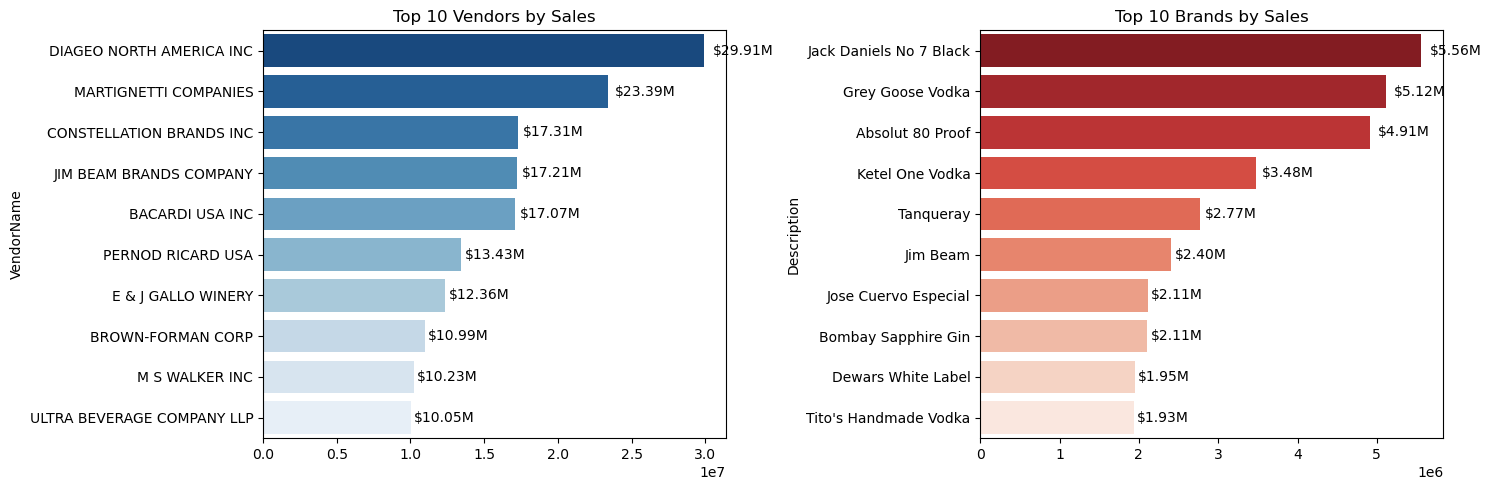

In [144]:
plt.figure(figsize=(15, 5))

# Plot for Top Vendors
plt.subplot(1, 2, 1)

ax1 = sns.barplot(
    y=top_vendors.index,
    x=top_vendors.values,
    palette="Blues_r"
)

plt.title("Top 10 Vendors by Sales")

for bar in ax1.patches:
    ax1.text(
        bar.get_width() + (bar.get_width() * 0.02),
        bar.get_y() + bar.get_height() / 2,
        format_dollars(bar.get_width()),
        ha='left',
        va='center',
        fontsize=10,
        color='black'
    )

# Plot for Top Brands
plt.subplot(1, 2, 2)

ax2 = sns.barplot(
    y=top_brands.index.astype(str),
    x=top_brands.values,
    palette="Reds_r"
)

plt.title("Top 10 Brands by Sales")

for bar in ax2.patches:
    ax2.text(
        bar.get_width() + (bar.get_width() * 0.02),
        bar.get_y() + bar.get_height() / 2,
        format_dollars(bar.get_width()),
        ha='left',
        va='center',
        fontsize=10,
        color='black'
    )

plt.tight_layout()
plt.show()

In [145]:
vendor_performance = df.groupby('VendorName').agg({
    'TotalPurchaseDollars':'sum',
    'GrossProfit':'sum',
    'TotalSalesDollars':'sum'
}).reset_index()
vendor_performance.shape

(108, 4)

In [146]:
vendor_performance['PurchaseContribution%'] = vendor_performance['TotalPurchaseDollars']/ vendor_performance['TotalPurchaseDollars'].sum()

In [147]:
vendor_performance = round(vendor_performance.sort_values('PurchaseContribution%', ascending = False),2)

In [148]:
# Display Top 10 Vendors

top_vendors = vendor_performance.head(10)

top_vendors['TotalSalesDollars'] = top_vendors['TotalSalesDollars'].apply(format_dollars)

top_vendors['TotalPurchaseDollars'] = top_vendors['TotalPurchaseDollars'].apply(format_dollars)

top_vendors['GrossProfit'] = top_vendors['GrossProfit'].apply(format_dollars)

top_vendors

,VendorName,TotalPurchaseDollars,GrossProfit,TotalSalesDollars,PurchaseContribution%
24,DIAGEO NORTH AMERICA INC,$26.95M,$2.96M,$29.91M,0.13
51,MARTIGNETTI COMPANIES,$18.38M,$5.01M,$23.39M,0.09
41,JIM BEAM BRANDS COMPANY,$15.61M,$1.60M,$17.21M,0.07
5,BACARDI USA INC,$15.14M,$1.93M,$17.07M,0.07
19,CONSTELLATION BRANDS INC,$13.64M,$3.67M,$17.31M,0.06
62,PERNOD RICARD USA,$12.25M,$1.18M,$13.43M,0.06
28,E & J GALLO WINERY,$10.18M,$2.18M,$12.36M,0.05
10,BROWN-FORMAN CORP,$10.10M,$898.04K,$10.99M,0.05
48,M S WALKER INC,$8.40M,$1.83M,$10.23M,0.04
97,ULTRA BEVERAGE COMPANY LLP,$7.92M,$2.13M,$10.05M,0.04


In [150]:
top_vendors['PurchaseContribution%'].sum()

np.float64(0.66)

In [151]:
top_vendors['Cumulative_Contribution%'] = top_vendors['PurchaseContribution%'].cumsum()
top_vendors

,VendorName,TotalPurchaseDollars,GrossProfit,TotalSalesDollars,PurchaseContribution%,Cumulative_Contribution%
24,DIAGEO NORTH AMERICA INC,$26.95M,$2.96M,$29.91M,0.13,0.13
51,MARTIGNETTI COMPANIES,$18.38M,$5.01M,$23.39M,0.09,0.22
41,JIM BEAM BRANDS COMPANY,$15.61M,$1.60M,$17.21M,0.07,0.29
5,BACARDI USA INC,$15.14M,$1.93M,$17.07M,0.07,0.36
19,CONSTELLATION BRANDS INC,$13.64M,$3.67M,$17.31M,0.06,0.42
62,PERNOD RICARD USA,$12.25M,$1.18M,$13.43M,0.06,0.48
28,E & J GALLO WINERY,$10.18M,$2.18M,$12.36M,0.05,0.53
10,BROWN-FORMAN CORP,$10.10M,$898.04K,$10.99M,0.05,0.58
48,M S WALKER INC,$8.40M,$1.83M,$10.23M,0.04,0.62
97,ULTRA BEVERAGE COMPANY LLP,$7.92M,$2.13M,$10.05M,0.04,0.66


In [152]:
# Recalculate Purchase Contribution in percentage

vendor_performance['PurchaseContribution%'] = (
    vendor_performance['TotalPurchaseDollars'] /
    vendor_performance['TotalPurchaseDollars'].sum()
) * 100

# Sort in descending order
vendor_performance = vendor_performance.sort_values(
    'PurchaseContribution%',
    ascending=False
)

# Select top 10 vendors
top_vendors = vendor_performance.head(10).copy()

# Calculate cumulative contribution
top_vendors['Cumulative_Contribution%'] = (
    top_vendors['PurchaseContribution%'].cumsum()
)

display(top_vendors[[
    'VendorName',
    'PurchaseContribution%',
    'Cumulative_Contribution%'
]])

,VendorName,PurchaseContribution%,Cumulative_Contribution%
24,DIAGEO NORTH AMERICA INC,12.800791,12.800791
51,MARTIGNETTI COMPANIES,8.728477,21.529268
41,JIM BEAM BRANDS COMPANY,7.414404,28.943672
5,BACARDI USA INC,7.192178,36.135850
19,CONSTELLATION BRANDS INC,6.476249,42.612099
62,PERNOD RICARD USA,5.818645,48.430744
28,E & J GALLO WINERY,4.834322,53.265067
10,BROWN-FORMAN CORP,4.795367,58.060434
48,M S WALKER INC,3.989609,62.050043
97,ULTRA BEVERAGE COMPANY LLP,3.763469,65.813512


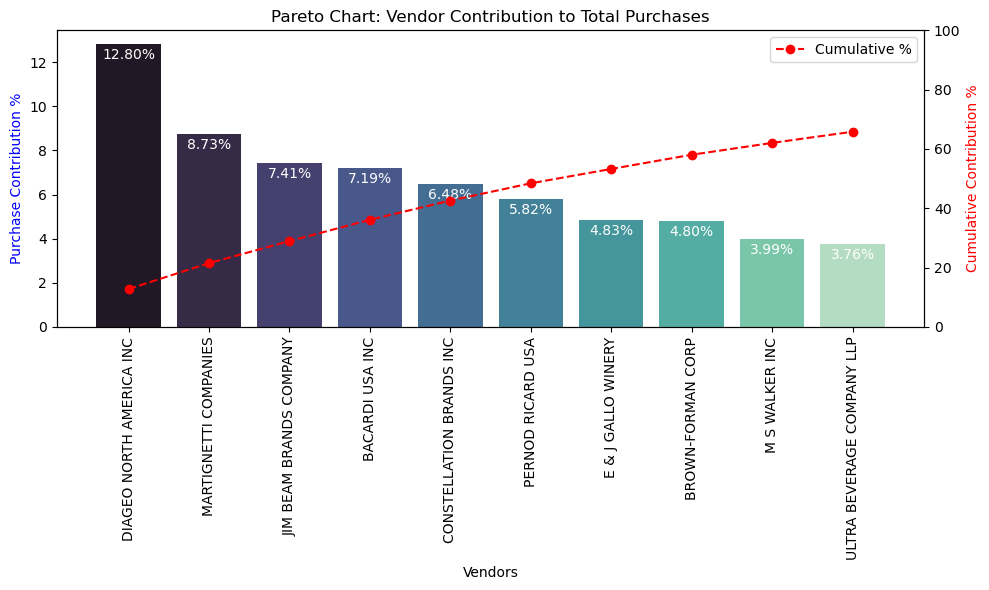

In [153]:
fig, ax1 = plt.subplots(figsize=(10, 6))

# Bar plot
sns.barplot(
    x=top_vendors['VendorName'],
    y=top_vendors['PurchaseContribution%'],
    palette="mako",
    ax=ax1
)

# Percentage labels
for i, value in enumerate(top_vendors['PurchaseContribution%']):
    ax1.text(
        i,
        value - 0.5,
        f'{value:.2f}%',
        ha='center',
        va='center',
        fontsize=10,
        color='white'
    )

# Cumulative contribution line
ax2 = ax1.twinx()

ax2.plot(
    range(len(top_vendors)),
    top_vendors['Cumulative_Contribution%'],
    color='red',
    marker='o',
    linestyle='dashed',
    label='Cumulative %'
)

ax1.set_xticks(range(len(top_vendors)))
ax1.set_xticklabels(top_vendors['VendorName'], rotation=90)

ax1.set_ylabel('Purchase Contribution %', color='blue')
ax2.set_ylabel('Cumulative Contribution %', color='red')

ax1.set_xlabel('Vendors')
ax1.set_title('Pareto Chart: Vendor Contribution to Total Purchases')

ax2.set_ylim(0, 100)
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

In [154]:
print(f"Total Purchase Contribution of top 10 vendors is {round(top_vendors['PurchaseContribution%'].sum(), 2)} %")

Total Purchase Contribution of top 10 vendors is 65.81 %


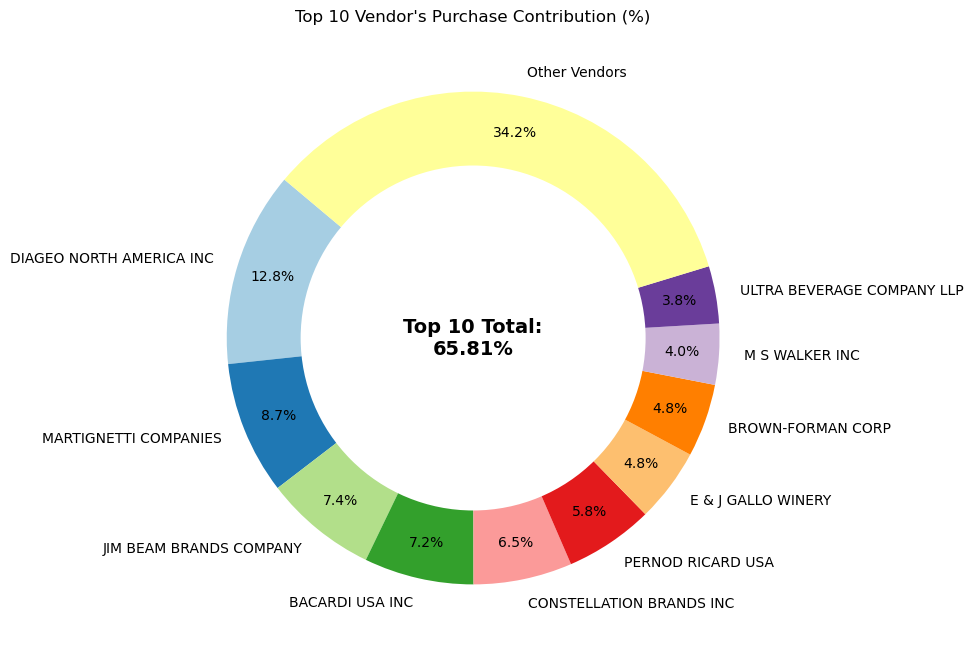

In [155]:

vendors = list(top_vendors['VendorName'].values)
purchase_contributions = list(top_vendors['PurchaseContribution%'].values)

total_contribution = sum(purchase_contributions)
remaining_contribution = 100 - total_contribution

# Append "Other Vendors" category
vendors.append("Other Vendors")
purchase_contributions.append(remaining_contribution)

# Donut Chart
fig, ax = plt.subplots(figsize=(8, 8))

wedges, texts, autotexts = ax.pie(
    purchase_contributions,
    labels=vendors,
    autopct='%1.1f%%',
    startangle=140,
    pctdistance=0.85,
    colors=plt.cm.Paired.colors
)

# Draw a white circle in the center to create a donut effect
centre_circle = plt.Circle((0, 0), 0.70, fc='white')
fig.gca().add_artist(centre_circle)

# Add Total Contribution annotation in the center
plt.text(
    0, 0,
    f"Top 10 Total:\n{total_contribution:.2f}%",
    fontsize=14,
    fontweight='bold',
    ha='center',
    va='center'
)

plt.title("Top 10 Vendor's Purchase Contribution (%)")
plt.show()

In [156]:
# Calculate Unit Purchase Price
df['UnitPurchasePrice'] = (
    df['TotalPurchaseDollars'] /
    df['TotalPurchaseQuantity']
)

# Categorize Order Size into Small, Medium and Large
df['OrderSize'] = pd.qcut(
    df['TotalPurchaseQuantity'],
    q=3,
    labels=["Small", "Medium", "Large"]
)

# Analyze Average Unit Purchase Price by Order Size
df.groupby('OrderSize', observed=False)['UnitPurchasePrice'].mean()

OrderSize
Small     42.639334
Medium    13.527864
Large      9.377130
Name: UnitPurchasePrice, dtype: float64

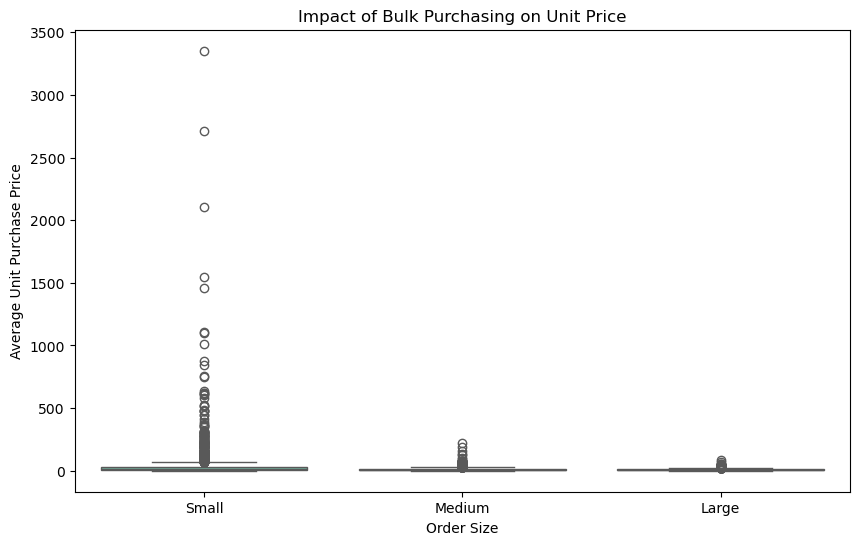

In [157]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="OrderSize",
    y="UnitPurchasePrice",
    palette="Set2"
)

plt.title("Impact of Bulk Purchasing on Unit Price")
plt.xlabel("Order Size")
plt.ylabel("Average Unit Purchase Price")

plt.show()

In [158]:
# Find vendors with Stock Turnover below 1
df[df['StockTurnover'] < 1] \
    .groupby('VendorName')['StockTurnover'] \
    .mean() \
    .sort_values(ascending=True) \
    .head(10)

VendorName
ALISA CARR BEVERAGES           0.500000
LABELLE VYDS AND WINERY        0.671482
Dunn Wine Brokers              0.679293
CANDIA VINEYARDS               0.686293
JEWELL TOWNE VINEYARDS         0.687032
INCREDIBREW INC                0.689863
SWEET BABY VINEYARD            0.690819
MOONLIGHT MEADERY              0.694161
STELLAR IMPORTING CO LLC       0.705020
HIGHLAND WINE MERCHANTS LLC    0.708333
Name: StockTurnover, dtype: float64

In [159]:
# Calculate Unsold Inventory Value
df['UnsoldInventoryValue'] = (
    (df['TotalPurchaseQuantity'] - df['TotalSalesQuantity'])
    * df['PurchasePrice']
)

print(
    'Total Unsold Capital:',
    format_dollars(df['UnsoldInventoryValue'].sum())
)

Total Unsold Capital: $42.65M


In [160]:
# Aggregate Capital Locked per Vendor
inventory_value_per_vendor = df.groupby('VendorName')[
    'UnsoldInventoryValue'
].sum().reset_index()

# Sort vendors with the highest locked capital
inventory_value_per_vendor = inventory_value_per_vendor.sort_values(
    by='UnsoldInventoryValue',
    ascending=False
)

# Format unsold inventory value
inventory_value_per_vendor['UnsoldInventoryValue'] = (
    inventory_value_per_vendor['UnsoldInventoryValue']
    .apply(format_dollars)
)

# Display top 10 vendors
inventory_value_per_vendor.head(10)

,VendorName,UnsoldInventoryValue
24,DIAGEO NORTH AMERICA INC,$5.44M
51,MARTIGNETTI COMPANIES,$3.59M
41,JIM BEAM BRANDS COMPANY,$3.26M
5,BACARDI USA INC,$3.07M
19,CONSTELLATION BRANDS INC,$3.00M
62,PERNOD RICARD USA,$2.66M
28,E & J GALLO WINERY,$2.39M
10,BROWN-FORMAN CORP,$2.33M
48,M S WALKER INC,$1.64M
73,SAZERAC CO INC,$1.34M


In [161]:
# Calculate 75th and 25th percentile thresholds

top_threshold = df['TotalSalesDollars'].quantile(0.75)
low_threshold = df['TotalSalesDollars'].quantile(0.25)

In [162]:
# Top-performing vendors
top_vendors = df[
    df['TotalSalesDollars'] >= top_threshold
]['ProfitMargin'].dropna()

# Low-performing vendors
low_vendors = df[
    df['TotalSalesDollars'] <= low_threshold
]['ProfitMargin'].dropna()

# Display results
print("Top-performing vendors:")
display(top_vendors.head())

print("Low-performing vendors:")
display(low_vendors.head())

Top-performing vendors:


0     0.831109
1     5.224678
2     4.950923
3     4.674346
4    10.744196
Name: ProfitMargin, dtype: float64

Low-performing vendors:


4200    0.030697
4240    6.535337
4247    3.967281
4258    1.742160
4261    7.707659
Name: ProfitMargin, dtype: float64

In [163]:
def confidence_interval(data, confidence=0.95):
    mean_val = np.mean(data)

    std_err = stats.sem(data, ddof=1)  # Standard error

    t_critical = stats.t.ppf(
        (1 + confidence) / 2,
        df=len(data) - 1
    )

    margin_of_error = t_critical * std_err

    return (
        mean_val,
        mean_val - margin_of_error,
        mean_val + margin_of_error
    )

Top Vendors 95% CI: (16.56, 17.85), Mean: 17.21
Low Vendors 95% CI: (42.53, 45.18), Mean: 43.86


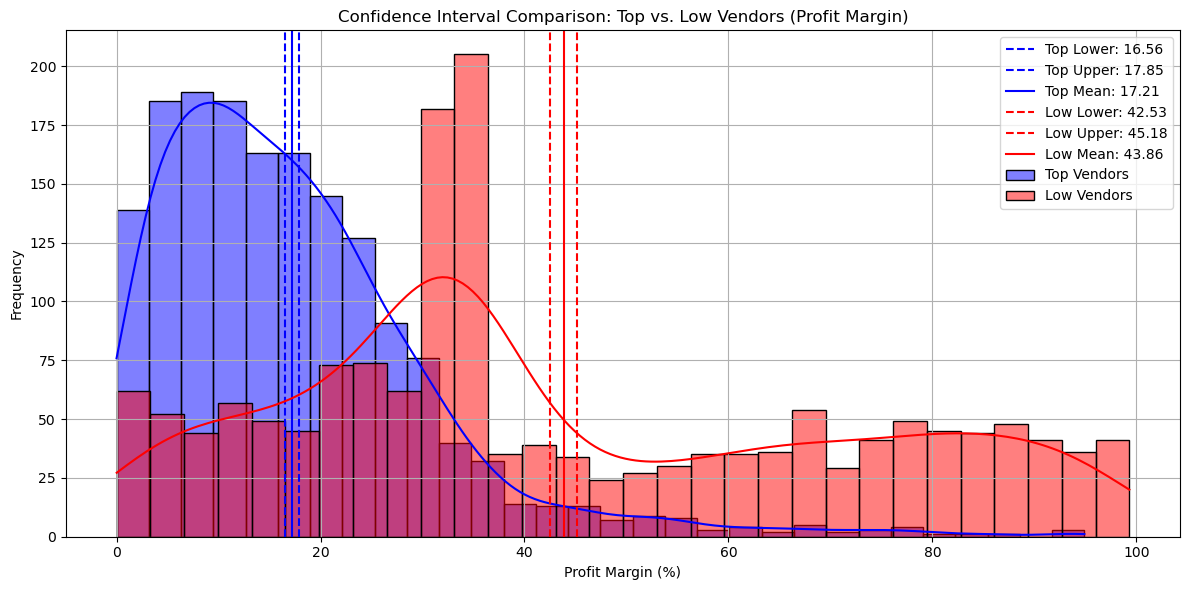

In [164]:
# Calculate confidence intervals
top_mean, top_lower, top_upper = confidence_interval(top_vendors)
low_mean, low_lower, low_upper = confidence_interval(low_vendors)

# Print confidence interval results
print(f"Top Vendors 95% CI: ({top_lower:.2f}, {top_upper:.2f}), Mean: {top_mean:.2f}")

print(f"Low Vendors 95% CI: ({low_lower:.2f}, {low_upper:.2f}), Mean: {low_mean:.2f}")

plt.figure(figsize=(12, 6))

# Top Vendors Plot
sns.histplot(
    top_vendors,
    kde=True,
    color="blue",
    bins=30,
    alpha=0.5,
    label="Top Vendors"
)

plt.axvline(top_lower, color="blue", linestyle="--",
            label=f"Top Lower: {top_lower:.2f}")

plt.axvline(top_upper, color="blue", linestyle="--",
            label=f"Top Upper: {top_upper:.2f}")

plt.axvline(top_mean, color="blue", linestyle="-",
            label=f"Top Mean: {top_mean:.2f}")

# Low Vendors Plot
sns.histplot(
    low_vendors,
    kde=True,
    color="red",
    bins=30,
    alpha=0.5,
    label="Low Vendors"
)

plt.axvline(low_lower, color="red", linestyle="--",
            label=f"Low Lower: {low_lower:.2f}")

plt.axvline(low_upper, color="red", linestyle="--",
            label=f"Low Upper: {low_upper:.2f}")

plt.axvline(low_mean, color="red", linestyle="-",
            label=f"Low Mean: {low_mean:.2f}")

# Finalize Plot
plt.title("Confidence Interval Comparison: Top vs. Low Vendors (Profit Margin)")
plt.xlabel("Profit Margin (%)")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.grid(True)
plt.show()

In [165]:
# Calculate sales thresholds
top_threshold = df["TotalSalesDollars"].quantile(0.75)
low_threshold = df["TotalSalesDollars"].quantile(0.25)

# Separate top and low-performing vendors
top_vendors = df[
    df["TotalSalesDollars"] >= top_threshold
]["ProfitMargin"].dropna()

low_vendors = df[
    df["TotalSalesDollars"] <= low_threshold
]["ProfitMargin"].dropna()

# Perform Two-Sample T-Test
t_stat, p_value = ttest_ind(
    top_vendors,
    low_vendors,
    equal_var=False
)

# Print results
print(f"T-Statistic: {t_stat:.4f}, P-Value: {p_value:.4f}")

if p_value < 0.05:
    print("Reject H0: There is a significant difference in profit margins between top and low-performing vendors.")
else:
    print("Fail to Reject H0: No significant difference in profit margins.")

T-Statistic: -35.4486, P-Value: 0.0000
Reject H0: There is a significant difference in profit margins between top and low-performing vendors.


In [3]:

import sqlite3
import pandas as pd

conn = sqlite3.connect('inventory.db')

purchase_data = pd.read_sql_query("""
    SELECT
        VendorNumber,
        VendorName,
        SUM(Dollars) AS TotalPurchaseDollars
    FROM purchases
    GROUP BY VendorNumber, VendorName
""", conn)

conn.close()

display(purchase_data.head(10))

,VendorNumber,VendorName,TotalPurchaseDollars
0,2,"IRA GOLDMAN AND WILLIAMS, LLP",5630.88
1,54,AAPER ALCOHOL & CHEMICAL CO,105.07
2,60,ADAMBA IMPORTS INTL INC,76770.25
3,105,ALTAMAR BRANDS LLC,11706.20
4,200,AMERICAN SPIRITS EXCHANGE,1205.16
5,287,APPOLO VINEYARDS LLC,2399.70
6,388,ATLANTIC IMPORTING COMPANY,41116.32
7,480,BACARDI USA INC,17624378.72
8,516,BANFI PRODUCTS CORP,1628866.68
9,653,STATE WINE & SPIRITS,1529682.04


In [4]:
# Calculate each vendor's percentage contribution
purchase_data['PurchaseContribution%'] = (
    purchase_data['TotalPurchaseDollars'] /
    purchase_data['TotalPurchaseDollars'].sum()
) * 100

# Sort vendors from highest to lowest contribution
purchase_data = purchase_data.sort_values(
    by='PurchaseContribution%',
    ascending=False
).reset_index(drop=True)

# Display top 10 vendors
display(purchase_data.head(10))

,VendorNumber,VendorName,TotalPurchaseDollars,PurchaseContribution%
0,3960,DIAGEO NORTH AMERICA INC,50959796.85,15.830903
1,4425,MARTIGNETTI COMPANIES,27821473.91,8.642873
2,12546,JIM BEAM BRANDS COMPANY,24203151.05,7.518824
3,17035,PERNOD RICARD USA,24124091.56,7.494263
4,480,BACARDI USA INC,17624378.72,5.475097
5,1392,CONSTELLATION BRANDS INC,15573917.90,4.838111
6,1128,BROWN-FORMAN CORP,13529433.08,4.202983
7,9165,ULTRA BEVERAGE COMPANY LLP,13210613.93,4.103940
8,3252,E & J GALLO WINERY,12289608.09,3.817825
9,9552,M S WALKER INC,10935817.30,3.397264


In [5]:
# Calculate total purchase value
total_purchase = purchase_data['TotalPurchaseDollars'].sum()

# Calculate contribution of top vendors
top_5 = purchase_data.head(5)['TotalPurchaseDollars'].sum()
top_10 = purchase_data.head(10)['TotalPurchaseDollars'].sum()
top_20 = purchase_data.head(20)['TotalPurchaseDollars'].sum()

# Calculate percentages
top_5_percentage = (top_5 / total_purchase) * 100
top_10_percentage = (top_10 / total_purchase) * 100
top_20_percentage = (top_20 / total_purchase) * 100

# Display results
print("VENDOR DEPENDENCY ANALYSIS")
print("--------------------------")
print(f"Top 5 Vendors:  {top_5_percentage:.2f}%")
print(f"Top 10 Vendors: {top_10_percentage:.2f}%")
print(f"Top 20 Vendors: {top_20_percentage:.2f}%")
print(f"Total Vendors:  {len(purchase_data)}")

VENDOR DEPENDENCY ANALYSIS
--------------------------
Top 5 Vendors:  44.96%
Top 10 Vendors: 65.32%
Top 20 Vendors: 83.62%
Total Vendors:  129


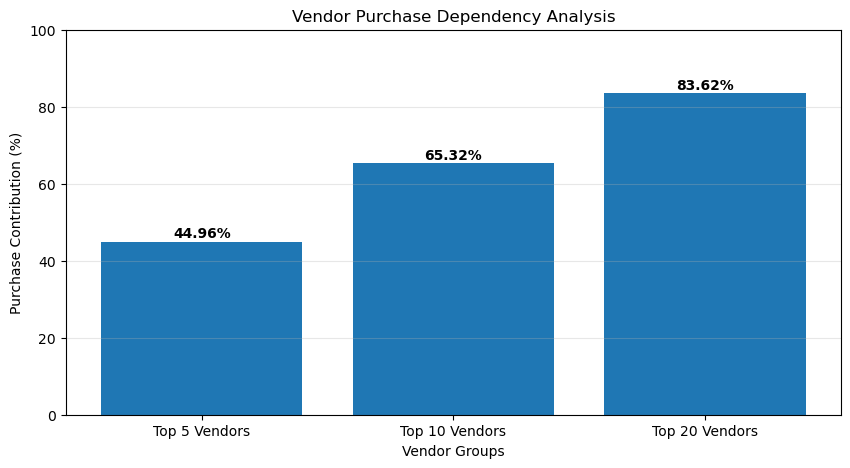

In [6]:
import matplotlib.pyplot as plt

# Prepare data for visualization
dependency_labels = ['Top 5 Vendors', 'Top 10 Vendors', 'Top 20 Vendors']
dependency_values = [
    top_5_percentage,
    top_10_percentage,
    top_20_percentage
]

# Create bar chart
plt.figure(figsize=(10, 5))

bars = plt.bar(
    dependency_labels,
    dependency_values
)

# Add percentage labels
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f'{height:.2f}%',
        ha='center',
        fontweight='bold'
    )

plt.title('Vendor Purchase Dependency Analysis')
plt.xlabel('Vendor Groups')
plt.ylabel('Purchase Contribution (%)')
plt.ylim(0, 100)
plt.grid(axis='y', alpha=0.3)

plt.show()

In [ ]:
### Business Insight – Vendor Dependency

#The analysis shows that 83.62% of total purchases come from just 20 out of 129 vendors. This indicates a high concentration of purchasing among a small group of suppliers. The company should monitor these key vendor relationships and explore alternative suppliers to reduce dependency risk.

In [7]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('inventory.db')

brand_data = pd.read_sql_query("""
    SELECT
        Brand,
        SUM(TotalSalesDollars) AS TotalSales,
        SUM(TotalPurchaseDollars) AS TotalPurchases,
        SUM(GrossProfit) AS GrossProfit,
        SUM(TotalSalesQuantity) AS TotalSalesQuantity
    FROM vendor_sales_summary
    GROUP BY Brand
""", conn)

conn.close()

display(brand_data.head(10))

,Brand,TotalSales,TotalPurchases,GrossProfit,TotalSalesQuantity
0,58,32687.98,32944.00,-256.02,2602.0
1,60,4281.00,12084.20,-7803.20,400.0
2,61,3357.60,3307.20,50.40,240.0
3,62,96622.76,91744.00,4878.76,2524.0
4,63,89495.78,86963.30,2532.48,2222.0
5,70,349.86,195.44,154.42,14.0
6,72,14286.16,11932.27,2353.89,384.0
7,75,284.81,109.40,175.41,19.0
8,77,106899.70,113583.48,-6683.78,7830.0
9,79,66406.49,55593.98,10812.51,4851.0


In [8]:
# Calculate profit margin for each brand
brand_data['ProfitMargin'] = (
    brand_data['GrossProfit'] /
    brand_data['TotalSales'].replace(0, float('nan'))
) * 100

# Sort brands by gross profit
brand_data = brand_data.sort_values(
    by='GrossProfit',
    ascending=False
).reset_index(drop=True)

# Display top 10 profitable brands
display(brand_data.head(10))

,Brand,TotalSales,TotalPurchases,GrossProfit,TotalSalesQuantity,ProfitMargin
0,4227,1321554.38,967725.98,353828.40,75062.0,26.773654
1,6570,1793517.34,1460072.36,333444.98,162282.0,18.591679
2,4260,1634155.30,1317439.48,316715.82,78970.0,19.381011
3,3489,2132902.80,1903739.55,229163.25,72520.0,10.744196
4,8068,3606744.46,3418303.68,188440.78,147904.0,5.224678
5,3876,888124.09,710919.90,177204.19,45791.0,19.952639
6,6682,786307.14,612328.41,173978.73,77286.0,22.126052
7,3802,1206709.78,1034996.38,171713.40,64322.0,14.229884
8,38370,763115.44,600612.60,162502.84,78772.0,21.294660
9,3545,3180678.98,3023206.01,157472.97,101402.0,4.950923


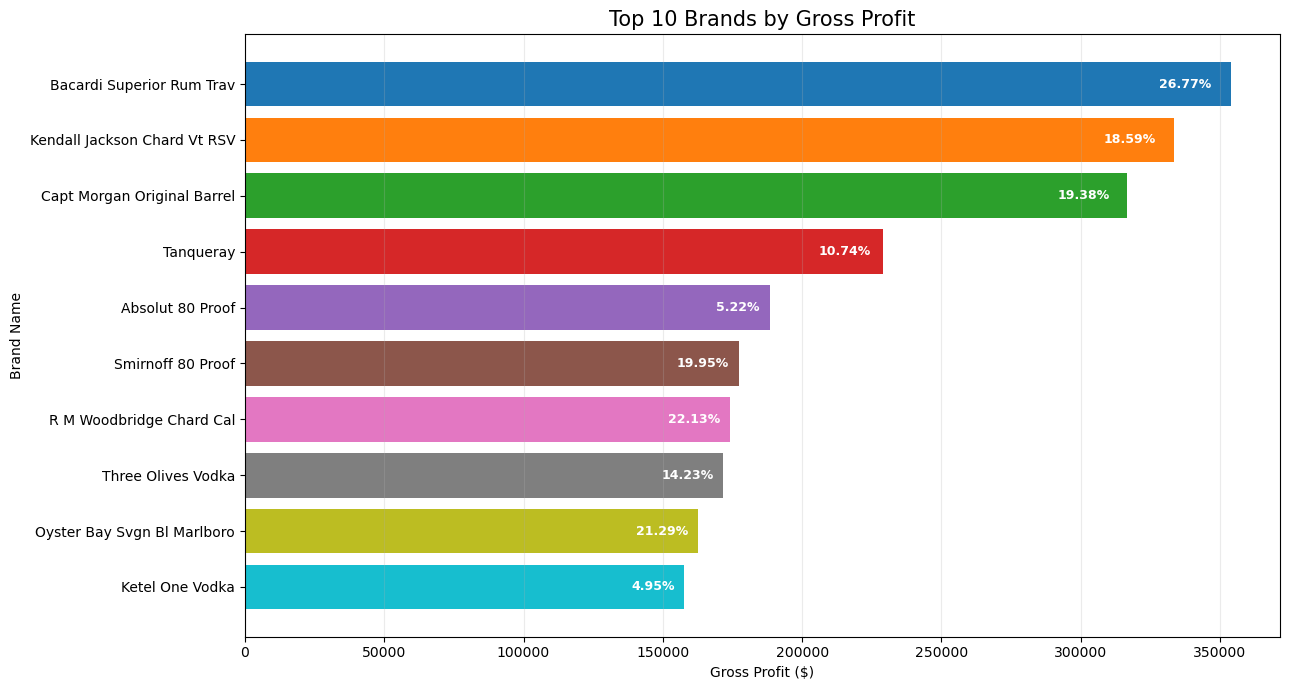

In [10]:
import matplotlib.pyplot as plt
import sqlite3
import pandas as pd

# Load brand descriptions from database
conn = sqlite3.connect('inventory.db')

brand_names = pd.read_sql_query("""
    SELECT Brand, MAX(Description) AS BrandName
    FROM purchase_prices
    GROUP BY Brand
""", conn)

conn.close()

# Merge brand descriptions with brand analysis
brand_data = brand_data.merge(
    brand_names,
    on='Brand',
    how='left'
)

# Select top 10 brands
top_10_brands = brand_data.head(10).copy()

# Use description where available
top_10_brands['BrandLabel'] = (
    top_10_brands['BrandName']
    .fillna(top_10_brands['Brand'].astype(str))
)

# Assign different colors
colors = plt.cm.tab10(range(len(top_10_brands)))

# Create chart
plt.figure(figsize=(13, 7))

bars = plt.barh(
    top_10_brands['BrandLabel'],
    top_10_brands['GrossProfit'],
    color=colors
)

# Add profit margin inside each bar
for bar, margin in zip(bars, top_10_brands['ProfitMargin']):
    width = bar.get_width()

    plt.text(
        width * 0.98,
        bar.get_y() + bar.get_height() / 2,
        f'{margin:.2f}%',
        ha='right',
        va='center',
        color='white',
        fontweight='bold',
        fontsize=9
    )

plt.title('Top 10 Brands by Gross Profit', fontsize=15)
plt.xlabel('Gross Profit ($)')
plt.ylabel('Brand Name')

plt.gca().invert_yaxis()
plt.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()

In [11]:
# Set minimum sales threshold at the 25th percentile
minimum_sales = brand_data['TotalSales'].quantile(0.25)

# Filter brands with sufficient sales
high_margin_brands = brand_data[
    (brand_data['TotalSales'] >= minimum_sales) &
    (brand_data['ProfitMargin'].notna())
].copy()

# Sort by profit margin
high_margin_brands = high_margin_brands.sort_values(
    by='ProfitMargin',
    ascending=False
).head(10)

# Display results
display(
    high_margin_brands[
        ['BrandName', 'TotalSales', 'GrossProfit', 'ProfitMargin']
    ]
)

,BrandName,TotalSales,GrossProfit,ProfitMargin
2561,Blue Chair Bay Coconut Rum,2691.81,2684.11,99.713947
3016,Pezzi King Svgn Bl Dry Creek,1987.47,1978.69,99.558232
1802,DiSaronno Amaretto,4613.40,4592.04,99.537001
2848,Skinnygirl Tangerine Vodka,2233.51,2222.73,99.517352
1853,Beniotome Sesame Shochu,4438.52,4416.31,99.499608
3887,M Chiarlo Gavi Wh,1055.04,1047.71,99.305240
3664,Rhone Roger Sabon 13 CDR Rou,1259.10,1249.71,99.254229
2546,L'Enclos de Viaud Lalande Po,2729.09,2708.41,99.242238
2313,Ch La Croix Lartigue 09,3197.18,3172.03,99.213369
1176,Soli White Blend,7878.14,7813.82,99.183564


In [12]:
# Calculate the 75th percentile sales threshold
minimum_sales = brand_data['TotalSales'].quantile(0.75)

print(f"Minimum Sales Threshold: ${minimum_sales:,.2f}")

# Filter brands with higher sales
high_margin_brands = brand_data[
    (brand_data['TotalSales'] >= minimum_sales) &
    (brand_data['ProfitMargin'].notna()) &
    (brand_data['ProfitMargin'] <= 100)
].copy()

# Select top 10 brands by profit margin
high_margin_brands = high_margin_brands.sort_values(
    by='ProfitMargin',
    ascending=False
).head(10)

display(
    high_margin_brands[
        ['BrandName', 'TotalSales', 'GrossProfit', 'ProfitMargin']
    ]
)

Minimum Sales Threshold: $21,429.90


,BrandName,TotalSales,GrossProfit,ProfitMargin
105,Jack Daniels No 7 Black Trav,51882.06,49232.91,94.893900
190,Saddleback Clrs 09 Cab Svgn,37990.00,35661.55,93.870887
152,Dewars Highlander Honey,42934.60,39707.32,92.483265
434,The Macallan Edition No 1,22497.75,20700.99,92.013601
310,Hirsch 20 Yr American Whisky,28994.28,26061.06,89.883453
312,Nicholson Ranch Chard Son Ct,28847.34,25910.07,89.817883
400,Absolut Spark Vodka,24560.14,21770.54,88.641759
241,Fort Ross Pnt Nr Sonoma Cst,36137.95,30904.75,85.518824
115,DiSaronna Amaretto Sour VAP,54822.95,46727.01,85.232571
408,Robert Hall Cab Svgn,25559.73,21409.35,83.762035


In [ ]:
"""Key findings
- Jack Daniels No 7 Black Trav ranks first with a 94.89% calculated profit margin.
- Saddleback Clrs 09 Cab Svgn ranks second at 93.87%.
- Dewars Highlander Honey ranks third at 92.48%.
- All 10 selected brands have calculated margins above 83%."""

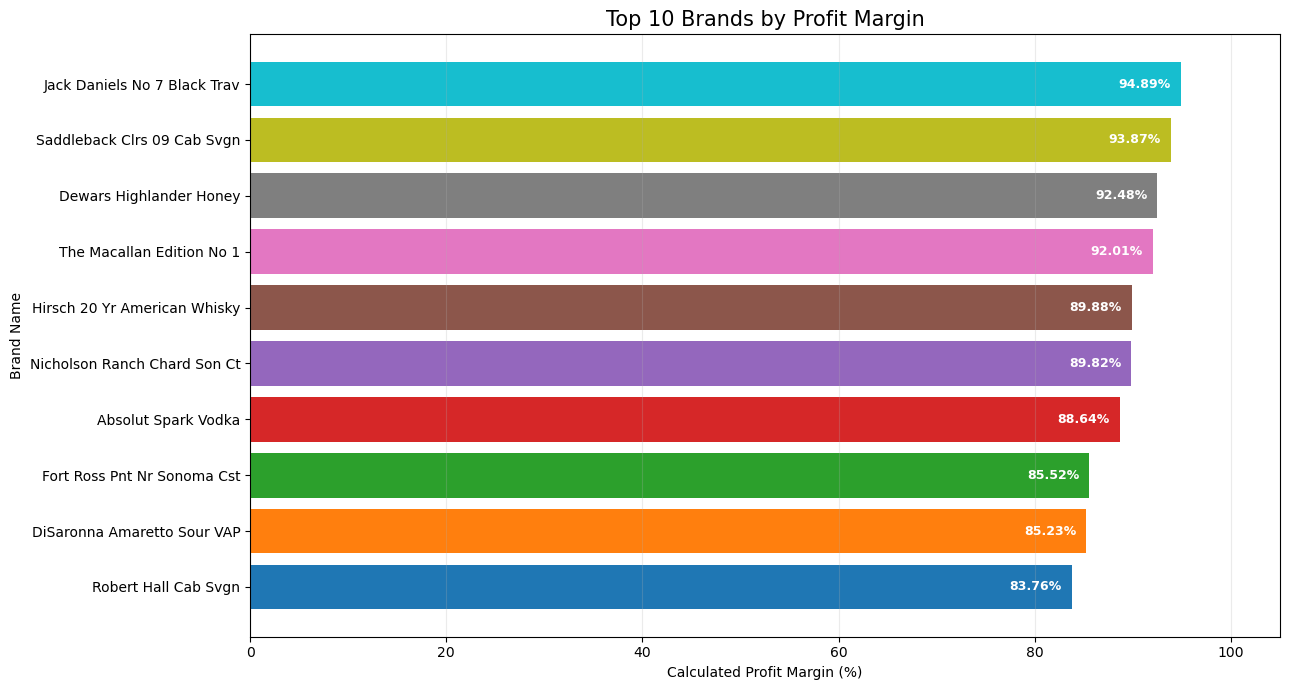

In [13]:
import matplotlib.pyplot as plt

# Prepare top 10 high-margin brands
plot_data = high_margin_brands.sort_values(
    by='ProfitMargin',
    ascending=True
).copy()

# Different color for every brand
colors = plt.cm.tab10(range(len(plot_data)))

# Create horizontal bar chart
plt.figure(figsize=(13, 7))

bars = plt.barh(
    plot_data['BrandName'],
    plot_data['ProfitMargin'],
    color=colors
)

# Add percentage labels inside bars
for bar in bars:
    width = bar.get_width()

    plt.text(
        width - 1,
        bar.get_y() + bar.get_height() / 2,
        f'{width:.2f}%',
        ha='right',
        va='center',
        color='white',
        fontweight='bold',
        fontsize=9
    )

plt.title('Top 10 Brands by Profit Margin', fontsize=15)
plt.xlabel('Calculated Profit Margin (%)')
plt.ylabel('Brand Name')

plt.xlim(0, 105)
plt.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()

In [14]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('inventory.db')

freight_data = pd.read_sql_query("""
    WITH PurchaseSummary AS (
        SELECT
            VendorNumber,
            VendorName,
            SUM(Dollars) AS TotalPurchaseDollars
        FROM purchases
        GROUP BY VendorNumber, VendorName
    ),

    FreightSummary AS (
        SELECT
            VendorNumber,
            SUM(Freight) AS TotalFreight
        FROM vendor_invoice
        GROUP BY VendorNumber
    )

    SELECT
        p.VendorNumber,
        p.VendorName,
        p.TotalPurchaseDollars,
        COALESCE(f.TotalFreight, 0) AS TotalFreight
    FROM PurchaseSummary p
    LEFT JOIN FreightSummary f
        ON p.VendorNumber = f.VendorNumber
""", conn)

conn.close()

display(freight_data.head(10))

,VendorNumber,VendorName,TotalPurchaseDollars,TotalFreight
0,2,"IRA GOLDMAN AND WILLIAMS, LLP",5630.88,27.08
1,54,AAPER ALCOHOL & CHEMICAL CO,105.07,0.48
2,60,ADAMBA IMPORTS INTL INC,76770.25,367.52
3,105,ALTAMAR BRANDS LLC,11706.20,62.39
4,200,AMERICAN SPIRITS EXCHANGE,1205.16,6.19
5,287,APPOLO VINEYARDS LLC,2399.70,12.28
6,388,ATLANTIC IMPORTING COMPANY,41116.32,211.74
7,480,BACARDI USA INC,17624378.72,89286.27
8,516,BANFI PRODUCTS CORP,1628866.68,8510.41
9,653,STATE WINE & SPIRITS,1529682.04,8014.98


In [15]:
# Calculate freight cost as a percentage of purchase value
freight_data['FreightCostPercentage'] = (
    freight_data['TotalFreight'] /
    freight_data['TotalPurchaseDollars'].replace(0, float('nan'))
) * 100

# Calculate freight cost per $100 of purchases
freight_data['FreightPer100Purchase'] = (
    freight_data['FreightCostPercentage']
)

# Sort vendors by freight cost percentage
freight_data = freight_data.sort_values(
    by='FreightCostPercentage',
    ascending=False
).reset_index(drop=True)

# Display vendors with highest freight cost percentage
display(
    freight_data[
        [
            'VendorName',
            'TotalPurchaseDollars',
            'TotalFreight',
            'FreightCostPercentage'
        ]
    ].head(15)
)

,VendorName,TotalPurchaseDollars,TotalFreight,FreightCostPercentage
0,MARTIGNETTI COMPANIES,40216.11,144929.24,360.376078
1,VINEYARD BRANDS LLC,10951.51,6070.09,55.426969
2,SOUTHERN GLAZERS W&S OF NE,40803.92,19016.59,46.604811
3,TALL SHIP DISTILLERY LLC,48445.58,259.90,0.536478
4,WESTERN SPIRITS BEVERAGE CO,361249.21,1933.19,0.535140
5,HIGHLAND WINE MERCHANTS LLC,5500.32,29.43,0.535060
6,ALTAMAR BRANDS LLC,11706.20,62.39,0.532965
7,DIAGEO CHATEAU ESTATE WINES,1365472.83,7259.75,0.531666
8,CANDIA VINEYARDS,36588.01,194.13,0.530584
9,LABELLE VYDS AND WINERY,146839.55,778.25,0.530000


In [16]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('inventory.db')

check_data = pd.read_sql_query("""
    SELECT
        p.VendorNumber,
        p.VendorName,
        COUNT(*) AS PurchaseRecords,
        SUM(p.Dollars) AS TotalPurchases,
        (
            SELECT COUNT(*)
            FROM vendor_invoice v
            WHERE v.VendorNumber = p.VendorNumber
        ) AS InvoiceRecords,
        (
            SELECT SUM(v.Freight)
            FROM vendor_invoice v
            WHERE v.VendorNumber = p.VendorNumber
        ) AS TotalFreight
    FROM purchases p
    WHERE p.VendorName IN (
        'MARTIGNETTI COMPANIES',
        'VINEYARD BRANDS LLC',
        'SOUTHERN GLAZERS W&S OF NE'
    )
    GROUP BY p.VendorNumber, p.VendorName
""", conn)

conn.close()

display(check_data)

,VendorNumber,VendorName,PurchaseRecords,TotalPurchases,InvoiceRecords,TotalFreight
0,4425,MARTIGNETTI COMPANIES,176487,27821473.91,82,144929.24


In [17]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('inventory.db')

freight_data = pd.read_sql_query("""
    WITH PurchaseSummary AS (
        SELECT
            VendorNumber,
            MAX(VendorName) AS VendorName,
            SUM(Dollars) AS TotalPurchaseDollars
        FROM purchases
        GROUP BY VendorNumber
    ),

    FreightSummary AS (
        SELECT
            VendorNumber,
            SUM(Freight) AS TotalFreight
        FROM vendor_invoice
        GROUP BY VendorNumber
    )

    SELECT
        p.VendorNumber,
        p.VendorName,
        p.TotalPurchaseDollars,
        COALESCE(f.TotalFreight, 0) AS TotalFreight
    FROM PurchaseSummary p
    LEFT JOIN FreightSummary f
        ON p.VendorNumber = f.VendorNumber
""", conn)

conn.close()

# Calculate freight percentage
freight_data['FreightCostPercentage'] = (
    freight_data['TotalFreight'] /
    freight_data['TotalPurchaseDollars'].replace(0, float('nan'))
) * 100

# Sort by freight percentage
freight_data = freight_data.sort_values(
    'FreightCostPercentage',
    ascending=False
).reset_index(drop=True)

display(freight_data.head(15))

,VendorNumber,VendorName,TotalPurchaseDollars,TotalFreight,FreightCostPercentage
0,28776,TALL SHIP DISTILLERY LLC,48445.58,259.90,0.536478
1,9625,WESTERN SPIRITS BEVERAGE CO,361249.21,1933.19,0.535140
2,3951,HIGHLAND WINE MERCHANTS LLC,5500.32,29.43,0.535060
3,105,ALTAMAR BRANDS LLC,11706.20,62.39,0.532965
4,1590,DIAGEO CHATEAU ESTATE WINES,1365472.83,7259.75,0.531666
5,90046,CANDIA VINEYARDS,36588.01,194.13,0.530584
6,90032,LABELLE VYDS AND WINERY,146839.55,778.25,0.530000
7,201359,FLAVOR ESSENCE INC,17.00,0.09,0.529412
8,9099,TRUETT HURST,236.64,1.25,0.528229
9,10050,Russian Standard Vodka,138907.27,732.60,0.527402


In [18]:
# Overall freight cost statistics
print("FREIGHT COST ANALYSIS")
print("---------------------")

print(f"Total Vendors: {len(freight_data)}")

print(
    f"Average Freight Cost: "
    f"{freight_data['FreightCostPercentage'].mean():.4f}%"
)

print(
    f"Median Freight Cost: "
    f"{freight_data['FreightCostPercentage'].median():.4f}%"
)

print(
    f"Minimum Freight Cost: "
    f"{freight_data['FreightCostPercentage'].min():.4f}%"
)

print(
    f"Maximum Freight Cost: "
    f"{freight_data['FreightCostPercentage'].max():.4f}%"
)

print(
    f"Total Freight: "
    f"${freight_data['TotalFreight'].sum():,.2f}"
)

print(
    f"Total Purchases: "
    f"${freight_data['TotalPurchaseDollars'].sum():,.2f}"
)

FREIGHT COST ANALYSIS
---------------------
Total Vendors: 126
Average Freight Cost: 0.5077%
Median Freight Cost: 0.5081%
Minimum Freight Cost: 0.4568%
Maximum Freight Cost: 0.5365%
Total Freight: $1,640,474.69
Total Purchases: $321,900,765.53


In [ ]:
### Business Insight – Freight Cost Analysis

#The analysis shows that total freight expenses are $1.64 million against total purchases of $321.90 million. The average freight cost ratio is 0.5077%, indicating that freight represents a relatively small and consistent portion of purchasing costs across vendors. No significant freight-cost outliers were identified after correcting the vendor aggregation.

In [19]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('inventory.db')

price_columns = pd.read_sql_query(
    "PRAGMA table_info(purchase_prices)",
    conn
)

display(price_columns)

conn.close()

,cid,name,type,notnull,dflt_value,pk
0,0,Brand,BIGINT,0,None,0
1,1,Description,TEXT,0,None,0
2,2,Price,FLOAT,0,None,0
3,3,Size,TEXT,0,None,0
4,4,Volume,TEXT,0,None,0
5,5,Classification,BIGINT,0,None,0
6,6,PurchasePrice,FLOAT,0,None,0
7,7,VendorNumber,BIGINT,0,None,0
8,8,VendorName,TEXT,0,None,0


In [20]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('inventory.db')

price_data = pd.read_sql_query("""
    SELECT
        Brand,
        Description,
        Price,
        PurchasePrice,
        VendorNumber,
        VendorName
    FROM purchase_prices
    LIMIT 15
""", conn)

conn.close()

display(price_data)

,Brand,Description,Price,PurchasePrice,VendorNumber,VendorName
0,58,Gekkeikan Black & Gold Sake,12.99,9.28,8320,SHAW ROSS INT L IMP LTD
1,62,Herradura Silver Tequila,36.99,28.67,1128,BROWN-FORMAN CORP
2,63,Herradura Reposado Tequila,38.99,30.46,1128,BROWN-FORMAN CORP
3,72,No. 3 London Dry Gin,34.99,26.11,9165,ULTRA BEVERAGE COMPANY LLP
4,75,Three Olives Tomato Vodka,14.99,10.94,7245,PROXIMO SPIRITS INC.
5,77,Three Olives Espresso Vodka,12.99,10.39,7245,PROXIMO SPIRITS INC.
6,79,Three Olives Loopy Vodka,14.99,9.62,7245,PROXIMO SPIRITS INC.
7,115,Belvedere Vodka,27.99,21.37,8112,MOET HENNESSY USA INC
8,126,Grey Goose Vodka,32.99,20.14,480,BACARDI USA INC
9,168,Three Olives Strawberry,12.99,8.95,7245,PROXIMO SPIRITS INC.


In [21]:
# Calculate price difference
price_data['PriceDifference'] = (
    price_data['Price'] - price_data['PurchasePrice']
)

# Calculate gross margin percentage
price_data['GrossMargin%'] = (
    price_data['PriceDifference'] /
    price_data['Price'].replace(0, float('nan'))
) * 100

# Calculate markup percentage
price_data['Markup%'] = (
    price_data['PriceDifference'] /
    price_data['PurchasePrice'].replace(0, float('nan'))
) * 100

# Sort by price difference
price_data = price_data.sort_values(
    by='PriceDifference',
    ascending=False
).reset_index(drop=True)

display(
    price_data[
        [
            'Description',
            'VendorName',
            'Price',
            'PurchasePrice',
            'PriceDifference',
            'GrossMargin%',
            'Markup%'
        ]
    ].head(15)
)

,Description,VendorName,Price,PurchasePrice,PriceDifference,GrossMargin%,Markup%
0,Gentleman Jack,BROWN-FORMAN CORP,49.99,36.76,13.23,26.465293,35.990207
1,Grey Goose Vodka,BACARDI USA INC,32.99,20.14,12.85,38.951197,63.803376
2,1800 Anejo Tequila,PROXIMO SPIRITS INC.,36.99,26.80,10.19,27.547986,38.022388
3,Wild Turkey Russell's RSV,CAMPARI AMERICA,29.99,20.76,9.23,30.776926,44.460501
4,No. 3 London Dry Gin,ULTRA BEVERAGE COMPANY LLP,34.99,26.11,8.88,25.378680,34.009958
5,Herradura Reposado Tequila,BROWN-FORMAN CORP,38.99,30.46,8.53,21.877404,28.003940
6,Herradura Silver Tequila,BROWN-FORMAN CORP,36.99,28.67,8.32,22.492566,29.019881
7,Milagro Anejo Tequila,WILLIAM GRANT & SONS INC,35.99,27.68,8.31,23.089747,30.021676
8,Hornitos Reposado VAP,JIM BEAM BRANDS COMPANY,22.99,14.70,8.29,36.059156,56.394558
9,Belvedere Vodka,MOET HENNESSY USA INC,27.99,21.37,6.62,23.651304,30.978007


In [22]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('inventory.db')

price_data = pd.read_sql_query("""
    SELECT
        Brand,
        Description,
        Price,
        PurchasePrice,
        VendorNumber,
        VendorName
    FROM purchase_prices
""", conn)

conn.close()

# Calculate price difference
price_data['PriceDifference'] = (
    price_data['Price'] - price_data['PurchasePrice']
)

# Calculate margin percentage
price_data['GrossMargin%'] = (
    price_data['PriceDifference'] /
    price_data['Price'].replace(0, float('nan'))
) * 100

# Calculate markup percentage
price_data['Markup%'] = (
    price_data['PriceDifference'] /
    price_data['PurchasePrice'].replace(0, float('nan'))
) * 100

print("Total Product Records:", len(price_data))
print("Unique Brands:", price_data['Brand'].nunique())
print("Unique Vendors:", price_data['VendorNumber'].nunique())

display(price_data.head(10))

Total Product Records: 12261
Unique Brands: 12261
Unique Vendors: 131


,Brand,Description,Price,PurchasePrice,VendorNumber,VendorName,PriceDifference,GrossMargin%,Markup%
0,58,Gekkeikan Black & Gold Sake,12.99,9.28,8320,SHAW ROSS INT L IMP LTD,3.71,28.560431,39.978448
1,62,Herradura Silver Tequila,36.99,28.67,1128,BROWN-FORMAN CORP,8.32,22.492566,29.019881
2,63,Herradura Reposado Tequila,38.99,30.46,1128,BROWN-FORMAN CORP,8.53,21.877404,28.003940
3,72,No. 3 London Dry Gin,34.99,26.11,9165,ULTRA BEVERAGE COMPANY LLP,8.88,25.378680,34.009958
4,75,Three Olives Tomato Vodka,14.99,10.94,7245,PROXIMO SPIRITS INC.,4.05,27.018012,37.020110
5,77,Three Olives Espresso Vodka,12.99,10.39,7245,PROXIMO SPIRITS INC.,2.60,20.015396,25.024062
6,79,Three Olives Loopy Vodka,14.99,9.62,7245,PROXIMO SPIRITS INC.,5.37,35.823883,55.821206
7,115,Belvedere Vodka,27.99,21.37,8112,MOET HENNESSY USA INC,6.62,23.651304,30.978007
8,126,Grey Goose Vodka,32.99,20.14,480,BACARDI USA INC,12.85,38.951197,63.803376
9,168,Three Olives Strawberry,12.99,8.95,7245,PROXIMO SPIRITS INC.,4.04,31.100847,45.139665


In [23]:
# Price variance statistics
print("PURCHASE PRICE VARIANCE SUMMARY")
print("--------------------------------")

print(f"Average Price Difference: ${price_data['PriceDifference'].mean():.2f}")
print(f"Median Price Difference: ${price_data['PriceDifference'].median():.2f}")
print(f"Highest Price Difference: ${price_data['PriceDifference'].max():.2f}")
print(f"Lowest Price Difference: ${price_data['PriceDifference'].min():.2f}")

# Check unusual records
print("\nDATA QUALITY CHECK")
print("-------------------")

print("Price Difference > 0:",
      (price_data['PriceDifference'] > 0).sum())

print("Price Difference = 0:",
      (price_data['PriceDifference'] == 0).sum())

print("Price Difference < 0:",
      (price_data['PriceDifference'] < 0).sum())

print("Missing Purchase Prices:",
      price_data['PurchasePrice'].isna().sum())

PURCHASE PRICE VARIANCE SUMMARY
--------------------------------
Average Price Difference: $12.15
Median Price Difference: $5.47
Highest Price Difference: $2888.87
Lowest Price Difference: $-11.19

DATA QUALITY CHECK
-------------------
Price Difference > 0: 12259
Price Difference = 0: 1
Price Difference < 0: 1
Missing Purchase Prices: 0


In [24]:
# Top 10 products with highest price differences
print("TOP 10 HIGHEST PRICE DIFFERENCES")

display(
    price_data.nlargest(10, 'PriceDifference')[
        [
            'Description',
            'VendorName',
            'Price',
            'PurchasePrice',
            'PriceDifference',
            'GrossMargin%'
        ]
    ]
)

# Bottom 10 products with lowest price differences
print("TOP 10 LOWEST PRICE DIFFERENCES")

display(
    price_data.nsmallest(10, 'PriceDifference')[
        [
            'Description',
            'VendorName',
            'Price',
            'PurchasePrice',
            'PriceDifference',
            'GrossMargin%'
        ]
    ]
)

TOP 10 HIGHEST PRICE DIFFERENCES


,Description,VendorName,Price,PurchasePrice,PriceDifference,GrossMargin%
9162,Glen Grant 50 Yr Scotch,CAMPARI AMERICA,13999.90,11111.03,2888.87,20.634933
9671,Patron En Lalique Tequila,ULTRA BEVERAGE COMPANY LLP,7499.99,5681.81,1818.18,24.242432
7428,Glenmorangie Pride,MOET HENNESSY USA INC,5799.99,4264.70,1535.29,26.470563
6061,Armand De Brignac Brut,ULTRA BEVERAGE COMPANY LLP,4222.99,2816.43,1406.56,33.307207
9211,Appleton Estate 50Yr Old Rum,CAMPARI AMERICA,4999.99,3649.63,1350.36,27.007254
7427,The Macallan M Decanter,EDRINGTON AMERICAS,4999.99,3787.87,1212.12,24.242448
5798,Hennessy Richard Cognac,MOET HENNESSY USA INC,4559.99,3352.93,1207.06,26.470672
10402,Port Ellen 32 Yr Single Malt,DIAGEO NORTH AMERICA INC,3699.99,2661.86,1038.13,28.057643
9132,Courvoisier L'Essence Cognac,JIM BEAM BRANDS COMPANY,3399.99,2518.51,881.48,25.925959
7430,Highland Park 1968,EDRINGTON AMERICAS,3999.99,3149.60,850.39,21.259803


TOP 10 LOWEST PRICE DIFFERENCES


,Description,VendorName,Price,PurchasePrice,PriceDifference,GrossMargin%
7915,None,BACARDI USA INC,0.00,11.19,-11.19,NaN
10803,The Macallan Double Cask 12,EDRINGTON AMERICAS,0.00,0.00,0.00,NaN
6888,Dr McGillicuddy's Apple Pie,SAZERAC CO INC,0.49,0.39,0.10,20.408163
7963,Dr McGillicuddy's Cherry,SAZERAC CO INC,0.49,0.39,0.10,20.408163
4913,Dr McGillicuddy's Root Beer,SAZERAC CO INC,0.49,0.38,0.11,22.448980
7962,Dr McGillicuddy's Vanilla,SAZERAC CO INC,0.49,0.38,0.11,22.448980
10558,Firefly Sweet Tea Vodka,SAZERAC CO INC,0.49,0.36,0.13,26.530612
7964,Dr McGillicuddy's Grape,SAZERAC CO INC,0.49,0.35,0.14,28.571429
790,UV Sangria Vodka,PHILLIPS PRODUCTS CO.,0.99,0.79,0.20,20.202020
1125,Skyy Infusions Blueberry,CAMPARI AMERICA,0.99,0.79,0.20,20.202020


In [25]:
# Identify invalid or suspicious price records

invalid_prices = price_data[
    (price_data['Price'] <= 0) |
    (price_data['PurchasePrice'] <= 0) |
    (price_data['Description'].isna())
]

print("DATA QUALITY REPORT")
print("-------------------")

print("Total Invalid Records:", len(invalid_prices))

print(
    "Zero or Negative Listed Prices:",
    (price_data['Price'] <= 0).sum()
)

print(
    "Zero or Negative Purchase Prices:",
    (price_data['PurchasePrice'] <= 0).sum()
)

print(
    "Missing Product Descriptions:",
    price_data['Description'].isna().sum()
)

display(invalid_prices)

DATA QUALITY REPORT
-------------------
Total Invalid Records: 2
Zero or Negative Listed Prices: 2
Zero or Negative Purchase Prices: 1
Missing Product Descriptions: 1


,Brand,Description,Price,PurchasePrice,VendorNumber,VendorName,PriceDifference,GrossMargin%,Markup%
7915,4202,None,0.0,11.19,480,BACARDI USA INC,-11.19,NaN,-100.0
10803,2166,The Macallan Double Cask 12,0.0,0.00,2561,EDRINGTON AMERICAS,0.00,NaN,NaN


In [26]:
# Create a separate cleaned dataset
clean_price_data = price_data[
    (price_data['Price'] > 0) &
    (price_data['PurchasePrice'] > 0) &
    (price_data['Description'].notna())
].copy()

# Recalculate price difference
clean_price_data['PriceDifference'] = (
    clean_price_data['Price'] -
    clean_price_data['PurchasePrice']
)

# Calculate gross margin percentage
clean_price_data['GrossMargin%'] = (
    clean_price_data['PriceDifference'] /
    clean_price_data['Price']
) * 100

# Calculate markup percentage
clean_price_data['Markup%'] = (
    clean_price_data['PriceDifference'] /
    clean_price_data['PurchasePrice']
) * 100

print("Original Records:", len(price_data))
print("Clean Records:", len(clean_price_data))
print("Excluded Records:", len(price_data) - len(clean_price_data))

display(clean_price_data.head())

Original Records: 12261
Clean Records: 12259
Excluded Records: 2


,Brand,Description,Price,PurchasePrice,VendorNumber,VendorName,PriceDifference,GrossMargin%,Markup%
0,58,Gekkeikan Black & Gold Sake,12.99,9.28,8320,SHAW ROSS INT L IMP LTD,3.71,28.560431,39.978448
1,62,Herradura Silver Tequila,36.99,28.67,1128,BROWN-FORMAN CORP,8.32,22.492566,29.019881
2,63,Herradura Reposado Tequila,38.99,30.46,1128,BROWN-FORMAN CORP,8.53,21.877404,28.003940
3,72,No. 3 London Dry Gin,34.99,26.11,9165,ULTRA BEVERAGE COMPANY LLP,8.88,25.378680,34.009958
4,75,Three Olives Tomato Vodka,14.99,10.94,7245,PROXIMO SPIRITS INC.,4.05,27.018012,37.020110


In [27]:
# Calculate vendor-level pricing efficiency
vendor_pricing = clean_price_data.groupby(
    'VendorName'
).agg(
    TotalProducts=('Brand', 'count'),
    TotalListedValue=('Price', 'sum'),
    TotalPurchaseCost=('PurchasePrice', 'sum'),
    TotalPriceDifference=('PriceDifference', 'sum')
).reset_index()

# Calculate weighted margin
vendor_pricing['WeightedMargin%'] = (
    vendor_pricing['TotalPriceDifference'] /
    vendor_pricing['TotalListedValue']
) * 100

# Consider vendors with at least 10 products
vendor_pricing = vendor_pricing[
    vendor_pricing['TotalProducts'] >= 10
].sort_values(
    'WeightedMargin%',
    ascending=False
)

display(vendor_pricing.head(10))

,VendorName,TotalProducts,TotalListedValue,TotalPurchaseCost,TotalPriceDifference,WeightedMargin%
108,SURVILLE ENTERPRISES CORP,22,298.78,183.98,114.80,38.422920
80,PERFECTA WINES,897,48703.19,30584.46,18118.73,37.202348
134,WINE GROUP INC,215,2078.85,1305.61,773.24,37.195565
11,BANFI PRODUCTS CORP,149,2342.31,1472.18,870.13,37.148371
29,DELICATO VINEYARDS INC,96,1234.64,776.90,457.74,37.074775
127,VINILANDIA USA,206,3763.54,2380.76,1382.78,36.741472
115,THE IMPORTED GRAPE LLC,40,747.10,473.32,273.78,36.645697
124,VINEXTRA INC,47,1351.53,857.51,494.02,36.552648
105,STE MICHELLE WINE ESTATES,144,2993.00,1917.93,1075.07,35.919479
117,TREASURY WINE ESTATES,111,1785.39,1145.24,640.15,35.854911


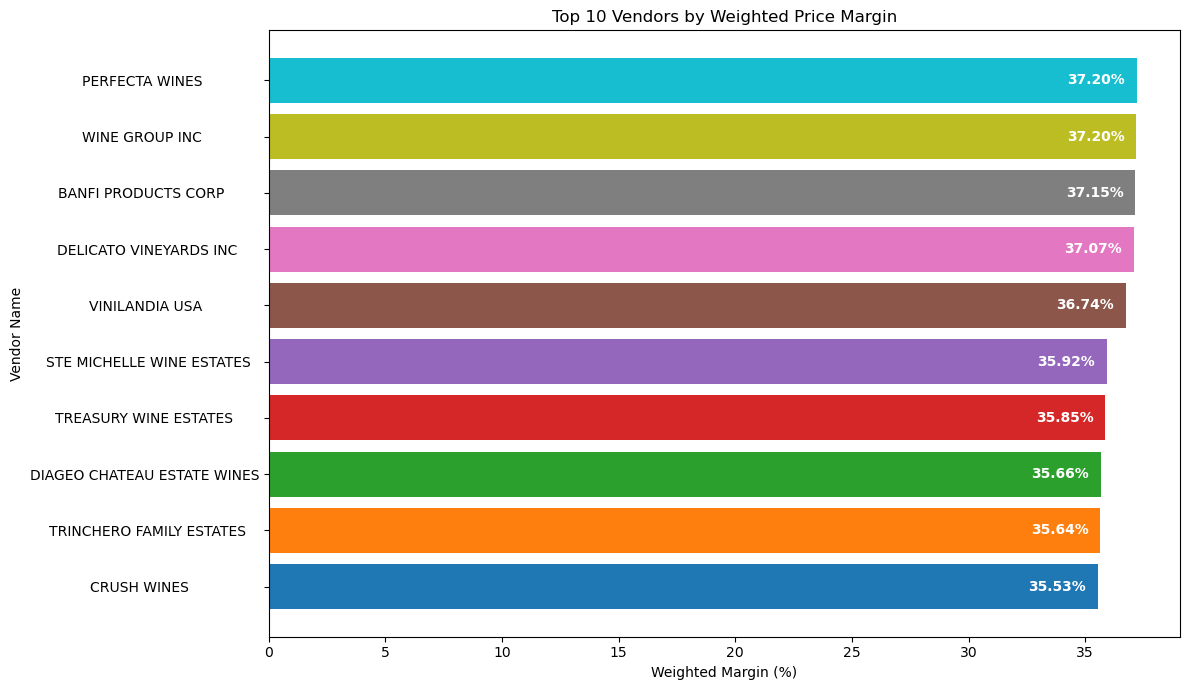

In [28]:
import matplotlib.pyplot as plt

# Exclude vendors with fewer than 50 products
plot_data = vendor_pricing[
    vendor_pricing['TotalProducts'] >= 50
].head(10).sort_values('WeightedMargin%')

plt.figure(figsize=(12, 7))

bars = plt.barh(
    plot_data['VendorName'],
    plot_data['WeightedMargin%'],
    color=plt.cm.tab10(range(len(plot_data)))
)

for bar in bars:
    width = bar.get_width()
    plt.text(
        width - 0.5,
        bar.get_y() + bar.get_height()/2,
        f'{width:.2f}%',
        ha='right',
        va='center',
        color='white',
        fontweight='bold'
    )

plt.title('Top 10 Vendors by Weighted Price Margin')
plt.xlabel('Weighted Margin (%)')
plt.ylabel('Vendor Name')
plt.tight_layout()
plt.show()

In [9]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('inventory.db')

for table in ['begin_inventory', 'end_inventory', 'sales']:
    print(f"\n--- {table.upper()} ---")
    display(pd.read_sql_query(
        f"SELECT * FROM {table} LIMIT 3",
        conn
    ))

conn.close()


--- BEGIN_INVENTORY ---


,InventoryId,Store,City,Brand,Description,Size,onHand,Price,startDate
0,1_HARDERSFIELD_58,1,HARDERSFIELD,58,Gekkeikan Black & Gold Sake,750mL,8,12.99,2024-01-01
1,1_HARDERSFIELD_60,1,HARDERSFIELD,60,Canadian Club 1858 VAP,750mL,7,10.99,2024-01-01
2,1_HARDERSFIELD_62,1,HARDERSFIELD,62,Herradura Silver Tequila,750mL,6,36.99,2024-01-01



--- END_INVENTORY ---


,InventoryId,Store,City,Brand,Description,Size,onHand,Price,endDate
0,1_HARDERSFIELD_58,1,HARDERSFIELD,58,Gekkeikan Black & Gold Sake,750mL,11,12.99,2024-12-31
1,1_HARDERSFIELD_62,1,HARDERSFIELD,62,Herradura Silver Tequila,750mL,7,36.99,2024-12-31
2,1_HARDERSFIELD_63,1,HARDERSFIELD,63,Herradura Reposado Tequila,750mL,7,38.99,2024-12-31



--- SALES ---


,InventoryId,Store,Brand,Description,Size,SalesQuantity,SalesDollars,SalesPrice,SalesDate,Volume,Classification,ExciseTax,VendorNo,VendorName
0,1_HARDERSFIELD_1004,1.0,1004.0,Jim Beam w/2 Rocks Glasses,750mL,1.0,16.49,16.49,2024-01-01,750.0,1.0,0.79,12546.0,JIM BEAM BRANDS COMPANY
1,1_HARDERSFIELD_1004,1.0,1004.0,Jim Beam w/2 Rocks Glasses,750mL,2.0,32.98,16.49,2024-01-02,750.0,1.0,1.57,12546.0,JIM BEAM BRANDS COMPANY
2,1_HARDERSFIELD_1004,1.0,1004.0,Jim Beam w/2 Rocks Glasses,750mL,1.0,16.49,16.49,2024-01-03,750.0,1.0,0.79,12546.0,JIM BEAM BRANDS COMPANY


In [10]:
import sqlite3
import pandas as pd
import numpy as np

conn = sqlite3.connect('inventory.db')

inventory_risk = pd.read_sql_query("""
    SELECT
        e.InventoryId,
        e.Store,
        e.City,
        e.Brand,
        e.Description,
        b.onHand AS BeginningStock,
        e.onHand AS EndingStock,
        COALESCE(s.TotalSales, 0) AS AnnualSales
    FROM end_inventory e

    LEFT JOIN begin_inventory b
        ON e.InventoryId = b.InventoryId

    LEFT JOIN (
        SELECT InventoryId, SUM(SalesQuantity) AS TotalSales
        FROM sales
        GROUP BY InventoryId
    ) s
        ON e.InventoryId = s.InventoryId
""", conn)

conn.close()

# Calculate average daily sales
inventory_risk['AverageDailySales'] = (
    inventory_risk['AnnualSales'] / 365
)

# Calculate inventory coverage days
inventory_risk['InventoryCoverageDays'] = np.where(
    inventory_risk['AverageDailySales'] > 0,
    inventory_risk['EndingStock'] /
    inventory_risk['AverageDailySales'],
    np.inf
)

# Classify inventory risk
inventory_risk['InventoryStatus'] = np.select(
    [
        inventory_risk['AnnualSales'] == 0,
        inventory_risk['InventoryCoverageDays'] < 30,
        inventory_risk['InventoryCoverageDays'] > 180
    ],
    [
        'Dead Stock',
        'Shortage Risk',
        'Excess Inventory'
    ],
    default='Healthy Inventory'
)

display(
    inventory_risk.sort_values(
        'InventoryCoverageDays',
        ascending=False
    ).head(15)
)

,InventoryId,Store,City,Brand,Description,BeginningStock,EndingStock,AnnualSales,AverageDailySales,InventoryCoverageDays,InventoryStatus
224467,81_PEMBROKE_46762,81,PEMBROKE,46762,Clayhouse Cab Svgn Paso Rbls,NaN,12,0.0,0.0,inf,Dead Stock
9,1_HARDERSFIELD_159,1,HARDERSFIELD,159,Glenmorangie Original VAP,NaN,8,0.0,0.0,inf,Dead Stock
224488,81_PEMBROKE_90604,81,PEMBROKE,90604,Ch Lynch Bages Pauilac,NaN,2,0.0,0.0,inf,Dead Stock
224480,81_PEMBROKE_90011,81,PEMBROKE,90011,Ch Pichon Longville 12 Pauil,NaN,3,0.0,0.0,inf,Dead Stock
224479,81_PEMBROKE_90010,81,PEMBROKE,90010,Ch Smith Haut Lafitte 12,NaN,12,0.0,0.0,inf,Dead Stock
224477,81_PEMBROKE_47014,81,PEMBROKE,47014,Juan Gil Jumilla Rd,NaN,22,0.0,0.0,inf,Dead Stock
224476,81_PEMBROKE_46985,81,PEMBROKE,46985,Rodney Strong Cab Svgn Alexa,NaN,10,0.0,0.0,inf,Dead Stock
224475,81_PEMBROKE_46947,81,PEMBROKE,46947,Murphy-Goode Merlot Alexandr,NaN,10,0.0,0.0,inf,Dead Stock
224473,81_PEMBROKE_46928,81,PEMBROKE,46928,Colome Malbec Calchaqui,NaN,6,0.0,0.0,inf,Dead Stock
224472,81_PEMBROKE_46923,81,PEMBROKE,46923,Torrontes Jelu San Juan,NaN,11,0.0,0.0,inf,Dead Stock


In [ ]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('inventory.db')

check = pd.read_sql_query("""
SELECT
    (SELECT COUNT(*) FROM end_inventory) AS EndingRecords,

    (SELECT COUNT(*)
     FROM end_inventory e
     INNER JOIN begin_inventory b
     ON TRIM(e.InventoryId) = TRIM(b.InventoryId)
    ) AS BeginningMatches,

    (SELECT COUNT(*)
     FROM end_inventory e
     INNER JOIN sales s
     ON TRIM(e.InventoryId) = TRIM(s.InventoryId)
    ) AS SalesMatches,

    (SELECT COUNT(DISTINCT InventoryId) FROM sales)
    AS UniqueSalesProducts

""", conn)

conn.close()
display(check)

In [1]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('inventory.db')

begin = pd.read_sql_query(
    "SELECT InventoryId FROM begin_inventory LIMIT 5", conn
)

ending = pd.read_sql_query(
    "SELECT InventoryId FROM end_inventory LIMIT 5", conn
)

print("BEGIN INVENTORY IDs:")
print(begin.to_string(index=False))

print("\nEND INVENTORY IDs:")
print(ending.to_string(index=False))

conn.close()

BEGIN INVENTORY IDs:
      InventoryId
1_HARDERSFIELD_58
1_HARDERSFIELD_60
1_HARDERSFIELD_62
1_HARDERSFIELD_63
1_HARDERSFIELD_72

END INVENTORY IDs:
      InventoryId
1_HARDERSFIELD_58
1_HARDERSFIELD_62
1_HARDERSFIELD_63
1_HARDERSFIELD_72
1_HARDERSFIELD_75


In [2]:
conn = sqlite3.connect('inventory.db')

test = pd.read_sql_query("""
    SELECT
        e.InventoryId,
        b.onHand AS BeginningStock,
        e.onHand AS EndingStock
    FROM end_inventory e
    LEFT JOIN begin_inventory b
        ON e.InventoryId = b.InventoryId
    WHERE e.InventoryId = '1_HARDERSFIELD_58'
""", conn)

conn.close()
display(test)

,InventoryId,BeginningStock,EndingStock
0,1_HARDERSFIELD_58,8,11


In [4]:
import sqlite3
import pandas as pd
import numpy as np

conn = sqlite3.connect('inventory.db')

# Load inventory snapshots with clear column names
ending = pd.read_sql_query("""
    SELECT InventoryId, Store, City, Brand, Description,
           onHand AS EndingStock
    FROM end_inventory
""", conn)

beginning = pd.read_sql_query("""
    SELECT InventoryId, onHand AS BeginningStock
    FROM begin_inventory
""", conn)

# Aggregate sales by inventory item
sales_summary = pd.read_sql_query("""
    SELECT InventoryId, SUM(SalesQuantity) AS AnnualSales
    FROM sales
    GROUP BY InventoryId
""", conn)

conn.close()

# Merge datasets
inventory_risk = ending.merge(
    beginning, on='InventoryId', how='left'
)

inventory_risk = inventory_risk.merge(
    sales_summary, on='InventoryId', how='left'
)

# Fill missing values
inventory_risk['BeginningStock'] = inventory_risk['BeginningStock'].fillna(0)
inventory_risk['AnnualSales'] = inventory_risk['AnnualSales'].fillna(0)

# Calculate inventory coverage
inventory_risk['CoverageDays'] = np.where(
    inventory_risk['AnnualSales'] > 0,
    inventory_risk['EndingStock'] * 365 /
    inventory_risk['AnnualSales'],
    np.nan
)

# Classify inventory risk
inventory_risk['InventoryStatus'] = np.select(
    [
        inventory_risk['AnnualSales'] == 0,
        inventory_risk['CoverageDays'] < 30,
        inventory_risk['CoverageDays'] > 180
    ],
    [
        'Dead Stock',
        'Shortage Risk',
        'Excess Inventory'
    ],
    default='Healthy Inventory'
)

display(inventory_risk.head(10))

,InventoryId,Store,City,Brand,Description,EndingStock,BeginningStock,AnnualSales,CoverageDays,InventoryStatus
0,1_HARDERSFIELD_58,1,HARDERSFIELD,58,Gekkeikan Black & Gold Sake,11,8.0,79.0,50.822785,Healthy Inventory
1,1_HARDERSFIELD_62,1,HARDERSFIELD,62,Herradura Silver Tequila,7,6.0,97.0,26.340206,Shortage Risk
2,1_HARDERSFIELD_63,1,HARDERSFIELD,63,Herradura Reposado Tequila,7,3.0,45.0,56.777778,Healthy Inventory
3,1_HARDERSFIELD_72,1,HARDERSFIELD,72,No. 3 London Dry Gin,4,6.0,2.0,730.000000,Excess Inventory
4,1_HARDERSFIELD_75,1,HARDERSFIELD,75,Three Olives Tomato Vodka,7,18.0,9.0,283.888889,Excess Inventory
5,1_HARDERSFIELD_77,1,HARDERSFIELD,77,Three Olives Espresso Vodka,18,7.0,104.0,63.173077,Healthy Inventory
6,1_HARDERSFIELD_79,1,HARDERSFIELD,79,Three Olives Loopy Vodka,7,2.0,86.0,29.709302,Shortage Risk
7,1_HARDERSFIELD_115,1,HARDERSFIELD,115,Belvedere Vodka,35,5.0,87.0,146.839080,Healthy Inventory
8,1_HARDERSFIELD_126,1,HARDERSFIELD,126,Grey Goose Vodka,36,17.0,367.0,35.803815,Healthy Inventory
9,1_HARDERSFIELD_159,1,HARDERSFIELD,159,Glenmorangie Original VAP,8,0.0,0.0,NaN,Dead Stock


In [5]:
# Inventory risk summary
risk_summary = inventory_risk.groupby(
    'InventoryStatus'
).agg(
    TotalProducts=('InventoryId', 'count'),
    TotalStock=('EndingStock', 'sum')
).reset_index()

risk_summary['Percentage'] = (
    risk_summary['TotalProducts'] /
    risk_summary['TotalProducts'].sum()
) * 100

display(risk_summary)

,InventoryStatus,TotalProducts,TotalStock,Percentage
0,Dead Stock,17761,264011,7.911746
1,Excess Inventory,71462,1695826,31.833186
2,Healthy Inventory,106976,2540480,47.653114
3,Shortage Risk,28290,385459,12.601954


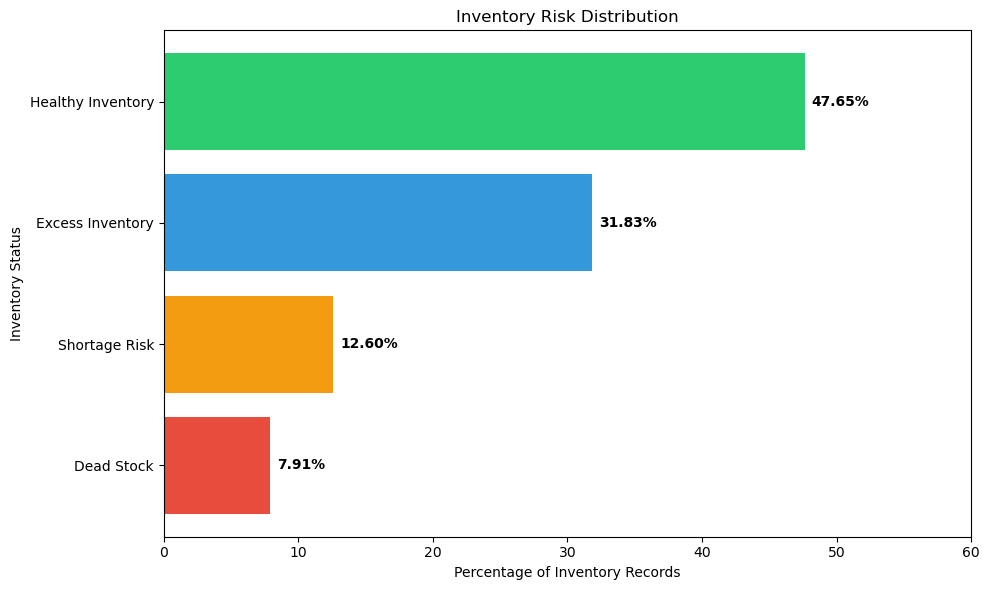

In [6]:
import matplotlib.pyplot as plt

risk_plot = risk_summary.sort_values(
    'Percentage',
    ascending=True
)

colors = ['#E74C3C', '#F39C12', '#3498DB', '#2ECC71']

plt.figure(figsize=(10, 6))

bars = plt.barh(
    risk_plot['InventoryStatus'],
    risk_plot['Percentage'],
    color=colors
)

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.5,
        bar.get_y() + bar.get_height()/2,
        f'{width:.2f}%',
        va='center',
        fontweight='bold'
    )

plt.title('Inventory Risk Distribution')
plt.xlabel('Percentage of Inventory Records')
plt.ylabel('Inventory Status')
plt.xlim(0, 60)
plt.tight_layout()
plt.show()

In [ ]:
### Business Insight – Inventory Risk Analysis

'''The analysis reveals that 31.83% of inventory records have excess stock, while 12.60% face potential stock shortage. Another 7.91% have stock but no recorded sales during the analysis period.

The business should review slow-moving products, improve stock replenishment planning, and investigate products with zero sales to reduce inventory holding costs and avoid stock shortages.'''

In [11]:
import sqlite3
import pandas as pd
import os

db_path = os.path.join(os.getcwd(), "inventory.db")
output_folder = os.path.join(os.getcwd(), "powerbi_data")

os.makedirs(output_folder, exist_ok=True)

conn = sqlite3.connect(db_path)

tables = conn.execute("""
    SELECT name FROM sqlite_master
    WHERE type='table'
    AND name NOT LIKE 'sqlite_%'
""").fetchall()

for (table,) in tables:
    df = pd.read_sql_query(
        f'SELECT * FROM "{table.replace(chr(34), chr(34)*2)}"',
        conn
    )

    filename = table.strip().replace(" ", "_") + ".csv"
    filepath = os.path.join(output_folder, filename)

    if os.path.exists(filepath):
        filename = table.replace(" ", "_").strip("_") + "_extra.csv"
        filepath = os.path.join(output_folder, filename)

    df.to_csv(filepath, index=False)

    print(f"{filename} | {len(df)} rows")

conn.close()

print("\nExport completed!")
print("Folder:", output_folder)

begin_inventory.csv | 206529 rows
end_inventory.csv | 224489 rows
purchases.csv | 2372474 rows
purchase_prices.csv | 12261 rows
sales.csv | 9907936 rows
vendor_invoice.csv | 5543 rows
vendor_sales_summary.csv | 10692 rows
vendor_sales_summary_extra.csv | 10648 rows

Export completed!
Folder: C:\Users\Rajvir\ data_vendor_performance\powerbi_data


In [12]:
import os

folder = os.path.join(os.getcwd(), "powerbi_data")

print("Exported CSV files:")
for f in os.listdir(folder):
    print(f)

Exported CSV files:
begin_inventory.csv
end_inventory.csv
purchases.csv
purchase_prices.csv
sales.csv
vendor_invoice.csv
vendor_sales_summary.csv
vendor_sales_summary_extra.csv


In [14]:
import pandas as pd

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(name, obj.shape)

begin (5, 1)
ending (224489, 6)
test (1, 3)
beginning (206529, 2)
sales_summary (254521, 2)
inventory_risk (224489, 10)
risk_summary (4, 4)
risk_plot (4, 4)
df (10648, 18)


In [15]:
print(df.columns.tolist())

['VendorNumber', 'VendorName', 'Brand', 'Description', 'PurchasePrice', 'ActualPrice', 'Volume', 'TotalPurchaseQuantity', 'TotalPurchaseDollars', 'TotalSalesQuantity', 'TotalSalesDollars', 'TotalSalesPrice', 'TotalExciseTax', 'FreightCost', 'GrossProfit', 'ProfitMargin', 'StockTurnover', 'SalesToPurchaseRatio']


In [16]:
import os
import pandas as pd

# 1. Brand Performance
BrandPerformance = df.groupby(
    ['Brand', 'Description']
).agg(
    TotalSales=('TotalSalesDollars', 'sum'),
    TotalPurchase=('TotalPurchaseDollars', 'sum'),
    GrossProfit=('GrossProfit', 'sum'),
    TotalSalesQuantity=('TotalSalesQuantity', 'sum')
).reset_index()

BrandPerformance['ProfitMargin'] = (
    BrandPerformance['GrossProfit'] /
    BrandPerformance['TotalSales'].replace(0, float('nan'))
) * 100


# 2. Low Turnover Vendor
LowTurnoverVendor = df.groupby('VendorName').agg(
    TotalPurchaseQuantity=('TotalPurchaseQuantity', 'sum'),
    TotalSalesQuantity=('TotalSalesQuantity', 'sum'),
    TotalPurchase=('TotalPurchaseDollars', 'sum'),
    TotalSales=('TotalSalesDollars', 'sum')
).reset_index()

LowTurnoverVendor['StockTurnover'] = (
    LowTurnoverVendor['TotalSalesQuantity'] /
    LowTurnoverVendor['TotalPurchaseQuantity'].replace(0, float('nan'))
)

LowTurnoverVendor = LowTurnoverVendor.sort_values(
    'StockTurnover'
)


# 3. Purchase Contribution
PurchaseContribution = df.groupby('VendorName').agg(
    TotalPurchase=('TotalPurchaseDollars', 'sum')
).reset_index()

PurchaseContribution['PurchaseContribution%'] = (
    PurchaseContribution['TotalPurchase'] /
    PurchaseContribution['TotalPurchase'].sum()
) * 100


# 4. Vendor Sales Summary
vendor_sales_summary = df.copy()


# Export all four tables
output_folder = os.path.join(os.getcwd(), 'powerbi_dashboard')
os.makedirs(output_folder, exist_ok=True)

tables = {
    'BrandPerformance': BrandPerformance,
    'LowTurnoverVendor': LowTurnoverVendor,
    'PurchaseContribution': PurchaseContribution,
    'vendor_sales_summary': vendor_sales_summary
}

for name, data in tables.items():
    data.to_csv(
        os.path.join(output_folder, name + '.csv'),
        index=False
    )
    print(name, data.shape)

print("\nAll four Power BI tables exported!")
print("Folder:", output_folder)

BrandPerformance (10648, 7)
LowTurnoverVendor (127, 6)
PurchaseContribution (127, 3)
vendor_sales_summary (10648, 18)

All four Power BI tables exported!
Folder: C:\Users\Rajvir\ data_vendor_performance\powerbi_dashboard


In [17]:
import os
import pandas as pd

output_folder = os.path.join(
    os.getcwd(), 'powerbi_dashboard_all'
)

os.makedirs(output_folder, exist_ok=True)

export_tables = {
    'vendor_sales_summary': 'df',
    'BrandPerformance': 'BrandPerformance',
    'LowTurnoverVendor': 'LowTurnoverVendor',
    'PurchaseContribution': 'PurchaseContribution',
    'VendorDependency': 'purchase_data',
    'FreightAnalysis': 'freight_data',
    'VendorPricingEfficiency': 'vendor_pricing',
    'BrandProfitability': 'brand_data',
    'HighMarginBrands': 'high_margin_brands',
    'TargetBrands': 'target_brands',
    'TopVendors': 'top_vendors',
    'TopBrands': 'top_brands',
    'PriceAnalysis': 'price_data',
    'CleanPriceAnalysis': 'clean_price_data',
    'InventoryRisk': 'inventory_risk',
    'InventoryRiskSummary': 'risk_summary'
}

export_count = 0

for filename, variable in export_tables.items():

    data = globals().get(variable)

    if isinstance(data, pd.Series):
        data = data.rename_axis('Name').reset_index(
            name='TotalSales'
        )

    if isinstance(data, pd.DataFrame):

        data.to_csv(
            os.path.join(output_folder, filename + '.csv'),
            index=False
        )

        print(f'{filename}.csv | {len(data)} rows')
        export_count += 1

# Export unsold inventory if available
if 'UnsoldInventoryValue' in df.columns:
    df[['VendorName', 'Brand', 'Description',
        'UnsoldInventoryValue']].to_csv(
        os.path.join(output_folder, 'UnsoldInventory.csv'),
        index=False
    )
    export_count += 1

print(f'\nTotal exported tables: {export_count}')
print('Folder:', output_folder)

vendor_sales_summary.csv | 10648 rows
BrandPerformance.csv | 10648 rows
LowTurnoverVendor.csv | 127 rows
PurchaseContribution.csv | 127 rows
InventoryRisk.csv | 224489 rows
InventoryRiskSummary.csv | 4 rows

Total exported tables: 6
Folder: C:\Users\Rajvir\ data_vendor_performance\powerbi_dashboard_all


In [18]:
import pandas as pd
import os

folder = os.path.join(os.getcwd(), 'powerbi_dashboard_all')

for filename in os.listdir(folder):
    if filename.endswith('.csv'):
        data = pd.read_csv(os.path.join(folder, filename))
        print(f'{filename}: {data.shape[0]} rows, {data.shape[1]} columns')

print("\nBrand grouping verification:")
print("Unique Brand-Description combinations:",
      df[['Brand', 'Description']].drop_duplicates().shape[0])

print("Original df rows:", len(df))

BrandPerformance.csv: 10648 rows, 7 columns
InventoryRisk.csv: 224489 rows, 10 columns
InventoryRiskSummary.csv: 4 rows, 4 columns
LowTurnoverVendor.csv: 127 rows, 6 columns
PurchaseContribution.csv: 127 rows, 3 columns
vendor_sales_summary.csv: 10648 rows, 18 columns

Brand grouping verification:
Unique Brand-Description combinations: 10648
Original df rows: 10648


In [19]:
print("Total unique Brands:", df['Brand'].nunique())

print("\nBrands with multiple descriptions:")
print(
    df.groupby('Brand')['Description']
      .nunique()
      .sort_values(ascending=False)
      .head(10)
)

print("\nSample Brand data:")
display(df[['Brand', 'Description']].head(10))

Total unique Brands: 10648

Brands with multiple descriptions:
Brand
90631    1
58       1
60       1
61       1
62       1
63       1
70       1
72       1
47090    1
47075    1
Name: Description, dtype: int64

Sample Brand data:


,Brand,Description
0,1233,Jack Daniels No 7 Black
1,3405,Tito's Handmade Vodka
2,8068,Absolut 80 Proof
3,4261,Capt Morgan Spiced Rum
4,3545,Ketel One Vodka
5,3858,Grey Goose Vodka
6,2589,Jameson Irish Whiskey
7,3102,Smirnoff Traveler
8,3489,Tanqueray
9,1376,Jim Beam


In [20]:
# Product Performance Analysis

ProductPerformance = df.groupby(
    ['Brand', 'Description']
).agg(
    TotalSales=('TotalSalesDollars', 'sum'),
    TotalPurchase=('TotalPurchaseDollars', 'sum'),
    GrossProfit=('GrossProfit', 'sum'),
    TotalSalesQuantity=('TotalSalesQuantity', 'sum')
).reset_index()

ProductPerformance['ProfitMargin'] = (
    ProductPerformance['GrossProfit'] /
    ProductPerformance['TotalSales'].replace(0, float('nan'))
) * 100

print("Product Performance:", ProductPerformance.shape)

display(ProductPerformance.head())

Product Performance: (10648, 7)


,Brand,Description,TotalSales,TotalPurchase,GrossProfit,TotalSalesQuantity,ProfitMargin
0,58,Gekkeikan Black & Gold Sake,32687.98,32944.0,-256.02,2602.0,-0.783224
1,60,Canadian Club 1858 VAP,4281.00,12084.2,-7803.20,400.0,-182.275169
2,61,Margaritaville Silver,3357.60,3307.2,50.40,240.0,1.501072
3,62,Herradura Silver Tequila,96622.76,91744.0,4878.76,2524.0,5.049287
4,63,Herradura Reposado Tequila,89495.78,86963.3,2532.48,2222.0,2.829720


In [21]:
ProductPerformance.to_csv(
    os.path.join(folder, 'ProductPerformance.csv'),
    index=False
)

print("ProductPerformance.csv exported successfully!")

ProductPerformance.csv exported successfully!
